# 신용 점수·연체 예측 — 한 단계씩 실행하며 배우기

가상의 고객 10,000명의 정보(나이, 소득, 부채 비율 등 6가지)로 두 가지를 예측한다.

- **신용 점수**(0~1000의 숫자) → 숫자를 맞히는 **회귀**
- **연체 여부**(0 = 정상, 1 = 연체) → 둘 중 하나를 고르는 **분류**

먼저 사람이 만든 if문 규칙으로 예측해 보고, 머신러닝 모델이 무엇을 더 잘하는지 숫자로 비교한다.

**사용법:** 위에서부터 한 셀씩 실행한다(전체 실행은 1분 이내). 코드를 한 줄씩 이해하지 못해도 괜찮다. 각 셀 아래의 **출력 읽기**가 출력에서 무엇을 보면 되는지 알려준다. **확인 질문**은 먼저 자기 말로 답해 본 뒤 접힌 답을 연다.

**구성:** 1~10장이 본편이다. 부록(A~E)은 더 알고 싶을 때 보는 확장이다. 데이터는 연습용으로 만든 합성 데이터라서, 결과를 실제 금융 고객에 대한 결론으로 읽지 않는다.

## 0. 준비

도구를 불러오고, 데이터 파일이 있는 프로젝트 폴더를 찾는다. 머신러닝 계산은 1장부터 시작한다.

In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_root = None
for candidate_folder in [Path.cwd()] + list(Path.cwd().parents):
    if (candidate_folder / "data_gen.py").is_file() and (candidate_folder / "src").is_dir():
        project_root = candidate_folder
        break

if project_root is None:
    raise FileNotFoundError("A5-1 폴더를 찾지 못했습니다. A5-1 또는 notebooks에서 실행하세요.")

RANDOM_STATE = 42  # 무작위 과정(분할 등)을 매번 같게 재현하기 위한 번호
pd.set_option("display.precision", 4)
print("프로젝트:", project_root.name)

프로젝트: A5-1


## 1. 데이터 — 입력과 정답

데이터는 함께 제공된 생성 코드(`data_gen.py`)로 만든다. 한 행이 고객 한 명이다.

In [2]:
data_path = project_root / "finance_data.csv"
if not data_path.exists():
    subprocess.run([sys.executable, str(project_root / "data_gen.py")],
                   cwd=project_root, check=True)

customers = pd.read_csv(data_path)
print("고객 수:", len(customers))
print("연체 비율:", customers["is_overdue"].mean())
display(customers.head())

고객 수: 10000
연체 비율: 0.1201


,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m,credit_score,is_overdue
0,50,3406.0,54,0.29,1,1,295.0,0
1,25,2161.0,7,0.78,2,0,259.0,1
2,56,6390.0,83,0.88,9,2,323.0,0
3,54,2821.0,10,0.01,2,2,377.0,0
4,50,4925.0,90,0.06,7,1,395.0,0


각 열의 뜻은 아래와 같다. 최솟값·최댓값은 실제 데이터에서 계산한다.

In [3]:
column_guide = pd.DataFrame({
    "column": ["age", "annual_income", "spending_score", "debt_ratio",
               "credit_card_count", "overdue_count_6m", "credit_score", "is_overdue"],
    "meaning": ["나이(세)",
                "연 소득(만원). 4000이면 연 4,000만 원",
                "소비 점수(1~99). 소비 성향을 점수로 나타낸 가상 지표",
                "소득 대비 부채 비율. 0.5면 빚이 연 소득의 절반",
                "보유 신용카드 수(장)",
                "최근 6개월 동안 연체한 횟수. 대부분 0회",
                "신용 점수 — 회귀 정답",
                "연체 여부(0 = 정상, 1 = 연체) — 분류 정답"],
    "used_to_make_answer": ["아니오", "예", "아니오", "예", "아니오", "예", "", ""],
}).set_index("column")
column_guide["min"] = customers.min()
column_guide["max"] = customers.max()
display(column_guide)

,meaning,used_to_make_answer,min,max
column,,,,
age,나이(세),아니오,20.0,69.0
annual_income,"연 소득(만원). 4000이면 연 4,000만 원",예,1500.0,12058.0
spending_score,소비 점수(1~99). 소비 성향을 점수로 나타낸 가상 지표,아니오,1.0,99.0
debt_ratio,소득 대비 부채 비율. 0.5면 빚이 연 소득의 절반,예,0.0,1.0
credit_card_count,보유 신용카드 수(장),아니오,1.0,9.0
overdue_count_6m,최근 6개월 동안 연체한 횟수. 대부분 0회,예,0.0,4.0
credit_score,신용 점수 — 회귀 정답,,78.0,676.0
is_overdue,"연체 여부(0 = 정상, 1 = 연체) — 분류 정답",,0.0,1.0


**정답을 만든 규칙:** 생성 코드는 신용 점수를 이 공식으로 만들었다.

> 신용 점수 = 300 + 0.03 × 연 소득(만원) − 50 × 연체 횟수 − 100 × 부채 비율 + 잡음(평균 0, 표준편차 30)

예를 들어 소득 5,000만 원, 연체 0회, 부채 비율 0.5인 고객은 300 + 150 − 0 − 50 = 400점 근처다. 그다음 신용 점수 하위 15%인 고객 중 무작위로 약 80%를 연체(1)로 표시했다. 그래서 전체의 약 12%가 연체다.

나이·소비 점수·카드 수는 공식에 없다. 생성 코드가 이 세 열을 다른 열과 무관하게 무작위 숫자로 뽑았기 때문에, 정답과 상관없는 **잡음 변수**다. 실제 고객 데이터라면 소비 패턴이 신용 상태와 관련 있을 수 있지만, 이 합성 데이터에는 그런 관계를 넣지 않았다. 실제 데이터에서는 이런 공식을 모르지만, 여기서는 정답 공식을 알고 있으니 모델이 이것을 얼마나 알아내는지 확인할 수 있다(10장).

**`is_overdue`가 뜻하는 것:** 이 열은 연체 위험을 따로 판단한 값이 아니라, 위 규칙으로 기계적으로 붙인 정답 표시다. 이 데이터에는 시점 정보(언제 대출했고 언제 연체했나)가 없다. 실제 서비스에서는 "과거에 대출한 고객이 일정 기간 안에 실제로 연체했는가"의 기록이 이 자리에 들어가고, 모델은 새 신청 고객의 입력으로 그 위험을 예측한다. 이 노트북의 분류 모델도 같은 역할을 흉내 낸다. 입력 6개를 보고 이 고객이 연체(1)로 표시될 확률을 낸다. `overdue_count_6m`은 별개의 열이다. 최근 6개월의 연체 횟수라는 **입력**이고, `is_overdue`는 맞혀야 할 **정답**이다.

머신러닝에서는 예측할 때 받는 정보를 **X(입력)**, 맞혀야 할 답을 **y(정답)**라고 부른다. 정답 열 두 개는 입력에서 뺀다. 특히 연체 라벨은 신용 점수로 만들었으므로, 신용 점수를 입력에 넣으면 답을 보고 문제를 푸는 셈이다. 이것을 **정답 누수**라고 한다.

In [4]:
feature_columns = [
    "age", "annual_income", "spending_score", "debt_ratio",
    "credit_card_count", "overdue_count_6m",
]
X = customers[feature_columns]
y_classification = customers["is_overdue"]   # 분류 정답: 0 또는 1
y_regression = customers["credit_score"]     # 회귀 정답: 점수

print("X의 크기 (행, 열):", X.shape)
display(X.head(3))

X의 크기 (행, 열): (10000, 6)


,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m
0,50,3406.0,54,0.29,1,1
1,25,2161.0,7,0.78,2,0
2,56,6390.0,83,0.88,9,2


**확인 질문:** 신용 점수도 숫자이고 연체 여부도 0/1 숫자인데, 왜 하나는 회귀이고 하나는 분류일까?
<details><summary>답 확인</summary>신용 점수는 크기에 의미가 있어 "얼마나 틀렸나"(오차)로 평가한다. 0/1은 정상/연체라는 두 범주에 붙인 이름표일 뿐이라 "맞혔나 틀렸나"로 평가한다. 숫자로 저장됐는지가 아니라 무엇을 예측하고 어떻게 평가하는지가 다르다.</details>

## 2. 분할 — 공부용 데이터와 시험용 데이터

모델이 본 데이터로 채점하면 실력을 알 수 없다. 그래서 고객을 8:2로 나눠 **Train**(학습용 8,000명)으로만 학습하고, **Test**(시험용 2,000명)는 마지막 채점에만 쓴다.

`stratify`는 두 묶음의 연체 비율을 비슷하게 맞추라는 뜻이다. 연체자가 12%뿐이라 그냥 나누면 한쪽에 몰릴 수 있다.

In [5]:
from sklearn.model_selection import train_test_split

(X_train, X_test,
 y_classification_train, y_classification_test,
 y_regression_train, y_regression_test) = train_test_split(
    X, y_classification, y_regression,
    test_size=0.2, random_state=RANDOM_STATE, stratify=y_classification,
)

display(pd.DataFrame({
    "customers": [len(X_train), len(X_test)],
    "overdue_rate": [y_classification_train.mean(), y_classification_test.mean()],
}, index=["Train", "Test"]))

,customers,overdue_rate
Train,8000,0.1201
Test,2000,0.1200


## 3. 사람이 만든 규칙으로 예측하기

학습 없이 if문만으로 예측하면 얼마나 맞힐까? 아래 6개 조건 중 하나라도 해당하면 연체(1), 아니면 정상(0)으로 판정한다. 이 규칙이 비교의 출발점(**베이스라인**)이 된다.

In [6]:
def predict_by_rules(customer):
    if customer["overdue_count_6m"] >= 2:
        return 1
    if customer["debt_ratio"] > 0.8:
        return 1
    if customer["annual_income"] < 3000:
        return 1
    if customer["overdue_count_6m"] >= 1 and customer["debt_ratio"] > 0.6:
        return 1
    if customer["annual_income"] < 4000 and customer["debt_ratio"] > 0.5:
        return 1
    if customer["credit_card_count"] >= 8:
        return 1
    return 0

# apply(..., axis=1): Test 고객을 한 명(한 행)씩 함수에 넣는다.
rule_predictions = X_test.apply(predict_by_rules, axis=1)
print("규칙이 연체로 판정한 고객:", rule_predictions.sum(), "/", len(rule_predictions))
print("실제 연체 고객:", y_classification_test.sum())

규칙이 연체로 판정한 고객: 1202 / 2000
실제 연체 고객: 240


**출력 읽기:** 실제 연체자는 240명인데 규칙은 그보다 훨씬 많은 고객을 연체로 찍었다. 많이 찍으면 연체자는 많이 잡지만, 정상 고객도 많이 걸린다. 이것을 정확히 세는 도구가 다음 장의 혼동행렬이다.

## 4. 결과 세기 — 혼동행렬과 평가 지표

분류 결과는 "실제"와 "예측"의 조합 네 칸으로 셀 수 있다. 이 표를 **혼동행렬**이라고 한다.

| | 예측: 정상 | 예측: 연체 |
| --- | --- | --- |
| **실제: 정상** | TN (맞게 통과) | FP (정상인데 연체로 찍음) |
| **실제: 연체** | FN (연체자를 놓침) | TP (연체자를 잡음) |

In [7]:
from sklearn.metrics import confusion_matrix

rule_matrix = confusion_matrix(y_classification_test, rule_predictions)
display(pd.DataFrame(rule_matrix,
                     index=["실제: 정상", "실제: 연체"],
                     columns=["예측: 정상", "예측: 연체"]))

tn, fp, fn, tp = rule_matrix.ravel()   # 네 칸을 순서대로 꺼낸다
print("TN:", tn, " FP:", fp, " FN:", fn, " TP:", tp)

,예측: 정상,예측: 연체
실제: 정상,792,968
실제: 연체,6,234


TN: 792  FP: 968  FN: 6  TP: 234


**출력 읽기:** 행(가로줄)은 실제, 열(세로줄)은 예측이다.

- 가로줄을 더하면 실제 인원이다. "실제: 정상" 줄의 합은 Test의 정상 고객 수, "실제: 연체" 줄의 합은 연체자 수(240명)다.
- 세로줄을 더하면 예측 인원이다. "예측: 연체" 열의 합은 3장에서 규칙이 연체로 판정한 고객 수와 같다.

TN·FP·FN·TP는 두 글자로 읽는다. 뒤 글자 **P/N**은 무엇으로 예측했나(Positive = 연체, Negative = 정상), 앞 글자 **T/F**는 그 예측이 맞았나(True = 맞음, False = 틀림)다. 예를 들어 FP는 "연체라고 예측했는데 틀렸다", 즉 정상 고객을 잘못 찍은 경우다.

이제 네 칸으로 주요 지표를 직접 계산한다.

- **Accuracy(정확도)** = 맞힌 수 / 전체 = (TN + TP) / 전체
- **Precision(정밀도)** = 연체로 찍은 사람 중 진짜 연체자 비율 = TP / (TP + FP)
- **Recall(재현율)** = 실제 연체자 중 잡아낸 비율 = TP / (TP + FN)
- **F1** = Precision과 Recall의 조화평균. 둘 중 하나라도 낮으면 F1도 낮다.

In [8]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_by_hand = (tn + tp) / (tn + fp + fn + tp)
precision_by_hand = tp / (tp + fp)
recall_by_hand = tp / (tp + fn)
f1_by_hand = 2 * precision_by_hand * recall_by_hand / (precision_by_hand + recall_by_hand)

display(pd.DataFrame({
    "by_hand": [accuracy_by_hand, precision_by_hand, recall_by_hand, f1_by_hand],
    "sklearn": [accuracy_score(y_classification_test, rule_predictions),
                precision_score(y_classification_test, rule_predictions),
                recall_score(y_classification_test, rule_predictions),
                f1_score(y_classification_test, rule_predictions)],
}, index=["accuracy", "precision", "recall", "f1"]))

,by_hand,sklearn
accuracy,0.5130,0.5130
precision,0.1947,0.1947
recall,0.9750,0.9750
f1,0.3245,0.3245


**출력 읽기:** 손으로 센 값과 라이브러리 값이 같다. 규칙은 Recall이 높지만(연체자를 거의 다 잡음) Precision이 낮다(연체로 찍은 다섯 명 중 네 명은 정상 고객).

**확인 질문:** 모든 고객을 "정상"이라고 예측하면 Accuracy와 F1은 어떻게 될까? 실행 전에 예상해 본다.

In [9]:
all_normal_predictions = np.zeros(len(y_classification_test), dtype=int)
print("모두 정상 — Accuracy:", accuracy_score(y_classification_test, all_normal_predictions))
print("모두 정상 — F1:", f1_score(y_classification_test, all_normal_predictions, zero_division=0))

모두 정상 — Accuracy: 0.88
모두 정상 — F1: 0.0


<details><summary>답 확인</summary>정상 고객이 88%이므로 Accuracy는 0.88로 높아 보인다. 하지만 연체자를 한 명도 잡지 못해 TP가 0이고 F1도 0이다. 한쪽이 훨씬 많은 데이터에서는 Accuracy만 보면 속는다. 그래서 이 노트북은 주로 F1을 함께 본다.</details>

## 5. 첫 머신러닝 모델 — 로지스틱 회귀

이름에 "회귀"가 붙었지만 0/1을 고르는 **분류** 모델이다. 네 단계로 진행한다.

1. **전처리:** 숫자 크기를 맞춘다.
2. **학습(`fit`):** Train으로 규칙을 배운다.
3. **예측(`predict`):** Test 고객을 판정한다.
4. **평가:** 4장의 지표로 채점한다.

전처리부터 한다. 소득(수천 단위)과 부채 비율(0~1)은 크기가 전혀 달라서, 각 열을 "평균 0, 표준편차 1"로 바꾼다(**표준화**). 비어 있는 값을 중앙값으로 채우는 단계도 넣는다. 이 데이터에는 빈 값이 없지만, 새 데이터에는 생길 수 있다.

### 5-0. 전처리에 쓰는 개념 셋: 표준편차, 표준화, 빈 값 채우기

- **표준편차**(standard deviation)는 값들이 평균에서 보통 얼마나 떨어져 있는지를 나타내는 수다. ① 값마다 평균과의 차이를 구하고 ② 제곱해서(음수와 양수가 서로 상쇄되지 않게) ③ 평균 내고 ④ 제곱근으로 단위를 되돌린다.
- **표준화**는 `(값 − 평균) ÷ 표준편차`다. 결과는 "평균에서 표준편차 몇 개만큼 떨어져 있나"이고, 단위(만원, 세, 회)가 사라진다. 바꾼 열은 평균이 0, 표준편차가 1이 된다.
- **`SimpleImputer`**는 빈 값(`NaN`)을 채우는 도구다. 로지스틱 회귀 등 많은 모델은 빈 값이 있으면 에러를 낸다. `strategy="median"`은 열마다 빈 값이 아닌 값들의 중앙값으로 채운다. 평균은 극단값 하나에 끌려가지만 중앙값은 덜 흔들린다.

세 가지를 값 몇 개로 직접 계산해 본다.

In [10]:
from sklearn.impute import SimpleImputer

# 표준편차: 평균과의 차이 → 제곱 → 평균 → 제곱근
toy_values = np.array([2, 4, 6])
differences = toy_values - toy_values.mean()
toy_std = np.sqrt((differences ** 2).mean())
print("평균:", toy_values.mean(), " 평균과의 차이:", differences)
print("표준편차(단계별 계산):", toy_std, " np.std:", toy_values.std())

# 표준화: (값 - 평균) / 표준편차
print("표준화한 값:", (toy_values - toy_values.mean()) / toy_std)

# 빈 값 채우기: 소득 열에 빈 값(np.nan)이 하나 있는 작은 예
toy_incomes = pd.DataFrame({"annual_income": [3000, 4000, np.nan, 100000]})
print("평균:", toy_incomes["annual_income"].mean(), " 중앙값:", toy_incomes["annual_income"].median())
print("median으로 채운 결과:", SimpleImputer(strategy="median").fit_transform(toy_incomes).ravel())

평균: 4.0  평균과의 차이: [-2.  0.  2.]
표준편차(단계별 계산): 1.632993161855452  np.std: 1.632993161855452
표준화한 값: [-1.22474487  0.          1.22474487]
평균: 35666.666666666664  중앙값: 4000.0
median으로 채운 결과: [  3000.   4000.   4000. 100000.]


**출력 읽기:** 평균과의 차이는 −2, 0, 2이고 표준편차는 약 1.63이다. 표준화하면 가운데 값은 0, 양쪽 값은 평균에서 표준편차의 약 1.2배 떨어진 위치(±1.22)가 된다. 빈 값은 4000으로 채워졌다. 평균(약 35667)은 100000 하나에 끌려 올라가서 나머지 고객들의 소득과 한참 멀다.

이 표준편차 계산은 `StandardScaler`가 쓰는 계산(`np.std`)과 같다.

중요한 점은 평균·중앙값 같은 기준을 **Train에서만** 배운다는 것이다. `fit_transform`은 "기준을 배우고 바꾸기", `transform`은 "이미 배운 기준으로 바꾸기"다.

In [11]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)   # Train으로 중앙값을 배우고 채움
X_test_imputed = imputer.transform(X_test)         # 배운 중앙값으로 채우기만 함

scaler = StandardScaler()
X_train_prepared = scaler.fit_transform(X_train_imputed)
X_test_prepared = scaler.transform(X_test_imputed)

display(pd.DataFrame({
    "before (Train)": X_train.iloc[0].to_numpy(),
    "after (Train)": X_train_prepared[0],
}, index=feature_columns))

,before (Train),after (Train)
age,40.00,-0.3316
annual_income,4613.00,-0.2182
spending_score,16.00,-1.1737
debt_ratio,0.98,1.6651
credit_card_count,7.00,0.7710
overdue_count_6m,0.00,-0.7060


**출력 읽기:** 첫 번째 Train 고객의 값이 표준화 전후로 어떻게 바뀌었는지 본다. 0보다 크면 평균보다 큰 값, 작으면 평균보다 작은 값이다.

### 5-1. `fit`과 `transform`은 각각 무엇을 하나

전처리 도구는 두 가지 일을 한다.

| 메서드 | 하는 일 | 표준화 도구(`StandardScaler`)의 경우 |
| --- | --- | --- |
| `fit(데이터)` | 데이터를 보고 **기준을 배워 저장**한다. 데이터는 바꾸지 않는다 | 열마다 평균과 표준편차를 계산해 `mean_`, `scale_`에 저장 |
| `transform(데이터)` | **저장된 기준으로** 데이터를 바꾼다. 새로 배우지 않는다 | 값마다 (값 − 저장된 평균) ÷ 저장된 표준편차 |
| `fit_transform(데이터)` | 같은 데이터로 `fit`한 뒤 곧바로 `transform`하는 줄임 | 위 두 단계를 한 번에 |

헷갈리기 쉬운 점: **Test는 "정답 데이터"가 아니다.** Test는 시험용으로 떼어 둔 고객 2,000명이고, 그 고객들의 입력(`X_test`)과 정답(`y_test`)이 모두 있다. 전처리는 입력에만 한다. 정답은 전처리하지 않는다. 핵심은 **기준(평균·표준편차)을 어느 고객들로 배우느냐**다. 아래에서 저장된 기준을 꺼내 직접 계산해 본다.

In [12]:
income_column = feature_columns.index("annual_income")
train_income_mean = scaler.mean_[income_column]    # fit이 Train에서 배워 저장한 값
train_income_std = scaler.scale_[income_column]
print("Train에서 배운 소득 평균:", train_income_mean, " 표준편차:", train_income_std)

first_test_income = X_test["annual_income"].iloc[0]
print("첫 Test 고객의 소득:", first_test_income)
print("직접 계산 (소득 - Train 평균) / Train 표준편차:", (first_test_income - train_income_mean) / train_income_std)
print("scaler.transform 결과:", X_test_prepared[0, income_column])

Train에서 배운 소득 평균: 5036.554375  표준편차: 1941.1620170128406
첫 Test 고객의 소득: 3559.0
직접 계산 (소득 - Train 평균) / Train 표준편차: -0.761170042505641
scaler.transform 결과: -0.761170042505641


**출력 읽기:** 직접 계산한 값과 `transform` 결과가 같다. `transform`은 Train에서 배운 평균·표준편차라는 "자"로 Test 고객을 잰 것이다.

만약 Test에 `fit_transform`을 쓰면 Test 고객 2,000명의 평균으로 자를 새로 만든다. 같은 고객이 어떻게 달라지는지 본다.

In [13]:
wrong_scaler = StandardScaler()
X_test_wrongly_prepared = wrong_scaler.fit_transform(X_test_imputed)   # 하면 안 되는 방법
print("Test로 새로 배운 소득 평균:", wrong_scaler.mean_[income_column])
print("같은 고객의 소득 — Train 기준 변환:", X_test_prepared[0, income_column])
print("같은 고객의 소득 — Test로 다시 배운 기준 변환:", X_test_wrongly_prepared[0, income_column])

Test로 새로 배운 소득 평균: 5021.689
같은 고객의 소득 — Train 기준 변환: -0.761170042505641
같은 고객의 소득 — Test로 다시 배운 기준 변환: -0.7670631491938821


**출력 읽기:** 같은 고객, 같은 소득인데 숫자가 달라졌다. 여기서는 Train과 Test의 평균이 비슷해 차이가 작다. 하지만 Test 고객의 분포가 다르면 차이가 커진다. 모델은 Train의 자로 잰 숫자에 맞춰 가중치를 배웠으므로, 자가 바뀌면 예측이 어긋난다. 또 시험지(Test)의 정보가 전처리 기준에 섞인다(**데이터 누수**).

이제 학습하고 예측한다. `predict_proba`는 고객마다 [정상일 확률, 연체일 확률] 두 숫자를 준다. `[:, 1]`은 그중 두 번째 열인 연체 확률만 꺼낸다.

In [14]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
logistic_model.fit(X_train_prepared, y_classification_train)

predicted_labels = logistic_model.predict(X_test_prepared)
overdue_probabilities = logistic_model.predict_proba(X_test_prepared)[:, 1]

display(pd.DataFrame({
    "actual": y_classification_test.to_numpy()[:8],
    "overdue_probability": overdue_probabilities[:8],
    "prediction": predicted_labels[:8],
}))

,actual,overdue_probability,prediction
0,1,0.1194,0
1,0,0.0228,0
2,0,0.0469,0
3,0,0.0063,0
4,1,0.8208,1
5,0,0.0185,0
6,1,0.5826,1
7,0,0.0004,0


**출력 읽기:** 확률이 0.5 이상인 고객이 1(연체)로 판정됐다. `predict`는 "연체 확률 ≥ 0.5이면 1"이라는 기준을 쓴다. 아래 셀에서 이것을 확인한다.

In [15]:
labels_at_half = (overdue_probabilities >= 0.5).astype(int)
print("predict와 '확률 >= 0.5' 판정이 모두 같은가:", np.array_equal(predicted_labels, labels_at_half))

predict와 '확률 >= 0.5' 판정이 모두 같은가: True


In [16]:
logistic_matrix = confusion_matrix(y_classification_test, predicted_labels)
display(pd.DataFrame(logistic_matrix,
                     index=["실제: 정상", "실제: 연체"],
                     columns=["예측: 정상", "예측: 연체"]))

display(pd.DataFrame({
    "rules": [accuracy_score(y_classification_test, rule_predictions),
              precision_score(y_classification_test, rule_predictions),
              recall_score(y_classification_test, rule_predictions),
              f1_score(y_classification_test, rule_predictions)],
    "logistic": [accuracy_score(y_classification_test, predicted_labels),
                 precision_score(y_classification_test, predicted_labels),
                 recall_score(y_classification_test, predicted_labels),
                 f1_score(y_classification_test, predicted_labels)],
}, index=["accuracy", "precision", "recall", "f1"]))

,예측: 정상,예측: 연체
실제: 정상,1703,57
실제: 연체,102,138


,rules,logistic
accuracy,0.5130,0.9205
precision,0.1947,0.7077
recall,0.9750,0.5750
f1,0.3245,0.6345


**출력 읽기:** 모델은 규칙보다 F1이 두 배 가까이 높다. 정상 고객을 덜 잘못 찍어서(FP 감소) Precision이 크게 올랐다. 대신 Recall은 내려갔다. 연체자 240명 중 100명 이상을 놓친다(FN).

**확인 질문:** 실제 서비스에서는 대출 신청 고객이 한 명씩 들어온다. 그 한 명에게 `fit_transform`을 쓰면 어떻게 될까?
<details><summary>답 확인</summary>고객 한 명의 평균은 그 사람 값 자체이고 표준편차는 0이다. 기준을 만들 수 없으니 변환이 의미를 잃는다(StandardScaler는 모든 값을 0으로 만든다). 그래서 학습할 때 Train으로 정한 기준을 저장해 두고, 새 고객에게는 `transform`만 쓴다. Test에 `transform`만 쓰는 것은 이 실제 상황을 흉내 낸 것이다.</details>

### 5-2. 로지스틱 회귀는 안에서 무엇을 계산하나

이 모델에는 은닉층이 없다. 신경망으로 비유하면 **층 하나, 뉴런 하나**이고, 계산은 세 단계다.

1. **점수 z:** `z = b + w₁x₁ + w₂x₂ + … + w₆x₆`. 선형 회귀와 같은 식이고, 값의 범위는 제한이 없다. `w`는 변수마다 하나인 가중치(`coef_`), `b`는 절편(`intercept_`)이다.
2. **확률 p:** `p = 1 / (1 + e^(−z))`. 이 **시그모이드** 함수가 어떤 z든 0~1 사이로 눌러 준다. z = 0이면 p = 0.5이고, z가 커지면 1에, 작아지면 0에 가까워진다.
3. **판정:** `p ≥ 0.5`이면 연체(1)다. 이것은 `z ≥ 0`과 같은 조건이다.

학습된 모델에서 `w`와 `b`를 꺼내 `predict_proba`를 직접 재현한다.

In [17]:
weights = logistic_model.coef_[0]        # 변수마다 w 하나 (6개)
bias = logistic_model.intercept_[0]      # b
display(pd.Series(weights, index=feature_columns, name="w"))
print("b:", bias)

scores = X_test_prepared[:5] @ weights + bias     # 점수 z. 고객마다 (변수 × w)의 합 + b
probabilities_by_hand = 1 / (1 + np.exp(-scores))
display(pd.DataFrame({
    "z": scores,
    "p (by hand)": probabilities_by_hand,
    "predict_proba": overdue_probabilities[:5],
}))

age                 -0.0255
annual_income       -2.4852
spending_score       0.0266
debt_ratio           1.2908
credit_card_count    0.0599
overdue_count_6m     1.4602
Name: w, dtype: float64

b: -4.277536435619691


,z,p (by hand),predict_proba
0,-1.9980,0.1194,0.1194
1,-3.7587,0.0228,0.0228
2,-3.0124,0.0469,0.0469
3,-5.0587,0.0063,0.0063
4,1.5217,0.8208,0.8208


**출력 읽기:** 직접 계산한 확률이 `predict_proba`와 같다. `w`의 부호와 크기가 모델이 배운 내용이다. 표준화한 입력이므로 w는 "그 변수가 표준편차 1만큼 클 때 z가 얼마나 변하나"다. 소득의 w는 음수(소득이 높으면 연체 확률 감소), 부채 비율과 연체 횟수의 w는 양수(증가)이고, 나이 등은 0에 가깝다.

**학습**은 이 `w`와 `b`를 고르는 일이다. 기준은 **로그 손실**(log loss)이다.

`손실 = −평균[ y·log(p) + (1−y)·log(1−p) ]`

실제 연체(y=1)인 고객의 p가 0.01이면 `−log(0.01)`이 커서 벌점이 크고, p가 0.99이면 거의 0이다. 확신하면서 틀릴수록 벌점이 급격히 커진다. 손실을 줄이는 방법은 **경사하강법**이다. 손실을 w로 미분한 기울기는 이렇게 단순하다.

`∂손실/∂wⱼ = 평균[ (p − y) · xⱼ ]` ("틀린 만큼 × 그 변수의 값")

기울기 반대 방향으로 w를 조금씩 옮기는 일을 반복한다. 연체자(y=1)를 p=0.3으로 예측했고 부채 변수가 +2라면 `(0.3−1)×2 = −1.4`로 기울기가 음수라서, 부채의 w가 커지는 쪽으로 움직인다. 그러면 다음번에 이 고객의 p가 올라간다. 이 과정을 직접 구현해서 sklearn과 비교한다.

In [18]:
y_train_values = y_classification_train.to_numpy()
learned_weights = np.zeros(len(feature_columns))   # 아무것도 모르는 상태에서 출발
learned_bias = 0.0
learning_rate = 0.5                                # 한 번에 움직이는 크기

for step in range(3001):
    p = 1 / (1 + np.exp(-(X_train_prepared @ learned_weights + learned_bias)))
    loss = -np.mean(y_train_values * np.log(p) + (1 - y_train_values) * np.log(1 - p))
    if step in (0, 10, 100, 3000):
        print("step", step, " 손실:", round(loss, 4))
    error = p - y_train_values                     # 틀린 만큼 (p - y)
    learned_weights -= learning_rate * (X_train_prepared.T @ error) / len(error)
    learned_bias -= learning_rate * error.mean()

no_penalty_model = LogisticRegression(C=np.inf, max_iter=2000)   # C=inf: 벌점 없음
no_penalty_model.fit(X_train_prepared, y_classification_train)
display(pd.DataFrame({
    "gradient descent (by hand)": np.append(learned_weights, learned_bias),
    "sklearn (no penalty)": np.append(no_penalty_model.coef_[0], no_penalty_model.intercept_[0]),
    "sklearn (default)": np.append(weights, bias),
}, index=feature_columns + ["bias"]))

step 0  손실: 0.6931
step 10  손실: 0.3381
step 100  손실: 0.1957


step 3000  손실: 0.1794


,gradient descent (by hand),sklearn (no penalty),sklearn (default)
age,-0.0254,-0.0256,-0.0255
annual_income,-2.5085,-2.5091,-2.4852
spending_score,0.0266,0.0267,0.0266
debt_ratio,1.3023,1.3026,1.2908
credit_card_count,0.0601,0.0605,0.0599
overdue_count_6m,1.4722,1.4725,1.4602
bias,-4.3077,-4.3081,-4.2775


**출력 읽기:** 처음에는 모든 고객의 p가 0.5라서 손실이 0.693(= log 2)이다. 반복할수록 손실이 줄고, 직접 구한 w가 sklearn과 거의 같은 값에 도달한다. sklearn은 같은 일을 더 똑똑한 방법(기본 `lbfgs`)으로 몇 번 만에 끝낸다. `max_iter=2000`은 이 반복 횟수의 상한이다.

세 번째 열(기본 설정)이 조금 작은 이유는 sklearn이 기본으로 **L2 벌점**을 더하기 때문이다. 손실에 `‖w‖²`에 비례하는 항을 더해 w가 지나치게 커지지 않게 누르는 장치이고, 세기는 `C`로 정하며 기본값은 1이다(`C`가 작을수록 벌점이 강하다). 첫 두 열은 벌점이 없다.

### 5-3. 표준화를 빼면 무엇이 달라지나

소득과 부채 비율의 크기가 달라도 이론상으로는 같은 답에 도달할 수 있다. 하지만 실제로는 두 가지가 문제가 된다.

- **학습이 어렵다.** 소득은 수천 단위라서 w가 아주 작아야 하고, 부채 비율은 0~1이라서 w가 커야 한다. 위 반복문의 `learning_rate` 하나로 두 w를 함께 맞추기 어렵다.
- **벌점이 불공평하다.** 작은 단위의 변수(부채 비율)는 효과를 내려면 w가 커야 해서 L2 벌점을 많이 받고, 큰 단위의 변수(소득)는 w가 작아도 되니 벌점을 거의 받지 않는다. 같은 정보량이어도 단위 때문에 대접이 달라진다.

표준화 없이 같은 모델을 학습해서 비교한다.

In [19]:
raw_model = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
raw_model.fit(X_train_imputed, y_classification_train)      # 표준화하지 않은 값

print("반복 횟수 — 표준화 O:", logistic_model.n_iter_[0], " 표준화 X:", raw_model.n_iter_[0])
print("Test F1  — 표준화 O:", f1_score(y_classification_test, predicted_labels),
      " 표준화 X:", f1_score(y_classification_test, raw_model.predict(X_test_imputed)))

display(pd.DataFrame({
    "standardized (per original unit)": weights / scaler.scale_,   # 표준편차당 w를 원래 단위당 w로 되돌림
    "raw": raw_model.coef_[0],
}, index=feature_columns))

반복 횟수 — 표준화 O: 10  표준화 X: 217
Test F1  — 표준화 O: 0.6344827586206897  표준화 X: 0.6344827586206897


,standardized (per original unit),raw
age,-0.0018,-0.0018
annual_income,-0.0013,-0.0013
spending_score,0.0009,0.0009
debt_ratio,4.4866,4.3303
credit_card_count,0.0233,0.0233
overdue_count_6m,2.0368,2.0144


**출력 읽기:** 표준화하지 않으면 수렴까지 걸리는 반복 횟수가 크게 늘어난다. 이 데이터에서는 예측 성능(F1)은 거의 같다. 즉 여기서 표준화는 결과를 바꾸기보다 계산을 쉽게 만든다. 표 두 열은 원래 단위(소득 1만원, 부채 비율 1 등)로 맞춘 w인데 비슷하지만, 벌점 때문에 완전히 같지는 않다.

표준화의 영향은 모델에 따라 다르다. 거리를 쓰는 방법(SMOTE, k-최근접 이웃)에서는 단위가 큰 변수가 거리를 지배하므로 표준화가 결과를 직접 바꾼다. 결정 나무는 크기 비교만 하므로 필요 없다.

## 6. 임계값 — 0.5는 바꿀 수 있다

5장의 모델은 연체자를 꽤 놓쳤다. 모델을 바꾸지 않고, 판정 기준(**임계값**)만 0.5에서 내려 보면 어떻게 될까?

In [20]:
threshold_rows = []
for threshold in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    labels_at_threshold = (overdue_probabilities >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "flagged": labels_at_threshold.sum(),
        "precision": precision_score(y_classification_test, labels_at_threshold),
        "recall": recall_score(y_classification_test, labels_at_threshold),
        "f1": f1_score(y_classification_test, labels_at_threshold),
    })
display(pd.DataFrame(threshold_rows))

,threshold,flagged,precision,recall,f1
0,0.2,345,0.5623,0.8083,0.6632
1,0.3,282,0.6454,0.7583,0.6973
2,0.4,237,0.6667,0.6583,0.6625
3,0.5,195,0.7077,0.5750,0.6345
4,0.6,151,0.7483,0.4708,0.5780
5,0.7,113,0.7611,0.3583,0.4873


**출력 읽기:** 임계값을 내리면 더 많은 고객을 연체로 찍는다(`flagged` 증가). 그러면 Recall은 오르고 Precision은 내려간다. 이 모델은 F1이 0.5보다 0.3 근처에서 더 높다. 같은 모델에서도 기준에 따라 판정과 지표가 바뀐다.

여기서는 변화를 관찰하려고 Test를 썼다. 실제로 임계값을 **정할** 때는 Test가 아니라 Train으로 정해야 한다(부록 B).

### 6-1. ROC 곡선과 AUC — 모든 임계값을 한 장에

임계값마다 지표가 바뀌니, 임계값 하나에 묶이지 않고 모델을 평가하는 방법이 필요하다.

**이름의 뜻:** ROC는 *Receiver Operating Characteristic*(수신자 조작 특성)의 줄임말이다. 2차 세계대전 때 레이더 신호에서 "진짜 비행기"와 "잡음"을 가려내는 성능을 평가하려고 만든 그래프라서 이런 이름이 붙었다. AUC는 *Area Under the Curve*, 곧 **곡선 아래 넓이**다.

**만드는 법:** 임계값 하나를 정하면 혼동행렬 하나가 나오고, 거기서 두 비율을 계산해 그래프에 **점 하나**를 찍는다.

- x축 **FPR(False Positive Rate, 오탐률)** = FP / (FP + TN) = 실제 정상 고객 중 연체로 잘못 찍힌 비율 (낮을수록 좋다)
- y축 **TPR(True Positive Rate)** = TP / (TP + FN) = 실제 연체자 중 잡아낸 비율. 4장의 Recall과 같다 (높을수록 좋다)

임계값을 1에서 0까지 내리며 찍은 점들을 이으면 ROC 곡선이 된다. 몇 개만 직접 계산해 본다.

In [21]:
roc_point_rows = []
for threshold in [0.9, 0.7, 0.5, 0.3, 0.1, 0.02]:
    labels_at_threshold = (overdue_probabilities >= threshold).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_classification_test, labels_at_threshold).ravel()
    roc_point_rows.append({
        "threshold": threshold,
        "FP": fp_t, "TN": tn_t, "TP": tp_t, "FN": fn_t,
        "FPR (x)": fp_t / (fp_t + tn_t),
        "TPR (y)": tp_t / (tp_t + fn_t),
    })
roc_points = pd.DataFrame(roc_point_rows)
display(roc_points)

,threshold,FP,TN,TP,FN,FPR (x),TPR (y)
0,0.90,8,1752,35,205,0.0045,0.1458
1,0.70,27,1733,86,154,0.0153,0.3583
2,0.50,57,1703,138,102,0.0324,0.5750
3,0.30,100,1660,182,58,0.0568,0.7583
4,0.10,283,1477,223,17,0.1608,0.9292
5,0.02,649,1111,240,0,0.3688,1.0000


**출력 읽기:** 임계값을 내릴수록 더 많은 고객을 연체로 찍으므로 두 비율이 모두 커진다. 연체자를 더 잡는 대신(TPR↑) 정상 고객도 더 잘못 찍는다(FPR↑). 좋은 모델은 FPR이 조금만 늘어도 TPR이 빠르게 오른다.

규칙의 곡선도 함께 그린다. 규칙은 0/1 판정 대신 "걸린 규칙의 개수"를 위험 점수로 쓴다. 개수가 많을수록 위험한 고객으로 본다.

In [22]:
def count_risk_rules(customer):
    count = 0
    count += int(customer["overdue_count_6m"] >= 2)
    count += int(customer["debt_ratio"] > 0.8)
    count += int(customer["annual_income"] < 3000)
    count += int(customer["overdue_count_6m"] >= 1 and customer["debt_ratio"] > 0.6)
    count += int(customer["annual_income"] < 4000 and customer["debt_ratio"] > 0.5)
    count += int(customer["credit_card_count"] >= 8)
    return count

rule_scores = X_test.apply(count_risk_rules, axis=1)

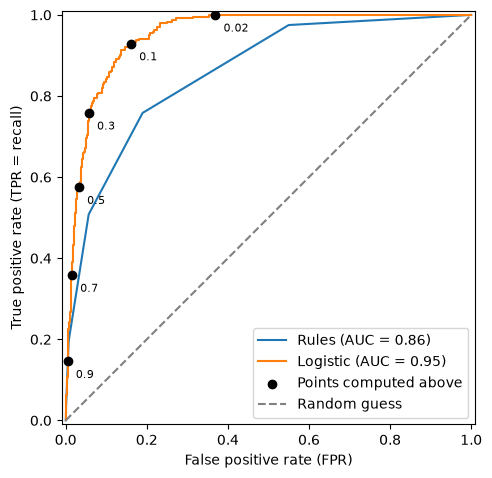

In [23]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(5, 5))
RocCurveDisplay.from_predictions(y_classification_test, rule_scores, ax=ax, name="Rules")
RocCurveDisplay.from_predictions(y_classification_test, overdue_probabilities, ax=ax, name="Logistic")
ax.scatter(roc_points["FPR (x)"], roc_points["TPR (y)"], color="black", zorder=3,
           label="Points computed above")
for _, point in roc_points.iterrows():
    ax.annotate(f'{point["threshold"]}', (point["FPR (x)"], point["TPR (y)"]),
                textcoords="offset points", xytext=(6, -12), fontsize=8)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
ax.set_xlabel("False positive rate (FPR)")
ax.set_ylabel("True positive rate (TPR = recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**출력 읽기:**

- 검은 점은 위 표에서 직접 계산한 점이고, 옆의 숫자는 그 점의 임계값이다. 로지스틱 곡선 위에 정확히 놓인다. 곡선은 이런 점을 모든 임계값에 대해 이은 것이다.
- **왼쪽 위 모서리**(FPR 0, TPR 1)는 정상 고객은 한 명도 잘못 찍지 않으면서 연체자는 모두 잡는 완벽한 상태다. 곡선이 이 모서리에 가깝게 붙을수록 좋은 모델이고, 그만큼 곡선 아래 넓이(AUC)도 1에 가까워진다.
- **회색 대각선**은 동전을 던져 판정하는 경우다. 무작위로 찍으면 정상 고객과 연체자가 같은 비율로 찍히므로 FPR = TPR이다. 넓이는 0.5다.
- 로지스틱 곡선이 규칙 곡선보다 전체적으로 위에 있다. 같은 오탐률에서 연체자를 더 많이 잡는다는 뜻이다. 범례 옆의 AUC 숫자로도 비교할 수 있다.

**넓이를 말로 바꾸면:** AUC는 이렇게도 해석된다.

> 연체자 한 명과 정상 고객 한 명을 무작위로 뽑았을 때, 모델이 연체자에게 더 높은 위험 점수를 줄 확률

실제로 무작위 쌍을 뽑아 확인한다.

In [24]:
from sklearn.metrics import roc_auc_score

y_test_array = y_classification_test.to_numpy()
overdue_scores = overdue_probabilities[y_test_array == 1]
normal_scores = overdue_probabilities[y_test_array == 0]

rng = np.random.default_rng(RANDOM_STATE)
picked_overdue = rng.choice(overdue_scores, size=10_000)
picked_normal = rng.choice(normal_scores, size=10_000)
print("무작위 10,000쌍에서 연체자 점수가 더 높은 비율:", np.mean(picked_overdue > picked_normal))
print("로지스틱 AUC (roc_auc_score):", roc_auc_score(y_classification_test, overdue_probabilities))
print("규칙 AUC (roc_auc_score):", roc_auc_score(y_classification_test, rule_scores))

무작위 10,000쌍에서 연체자 점수가 더 높은 비율: 0.9488
로지스틱 AUC (roc_auc_score): 0.9505089962121213
규칙 AUC (roc_auc_score): 0.8589251893939394


**출력 읽기:** 무작위 쌍으로 센 비율과 AUC가 거의 같다. 그래서 AUC는 "위험한 순서대로 얼마나 잘 줄 세우는가"를 잰다고 말한다. 임계값을 정하기 전 단계의 실력이므로, 임계값에 따라 바뀌는 F1과 함께 본다.

## 7. Pipeline — 지금까지의 단계를 하나로 묶기

5장에서 빈 값 채우기 → 표준화 → 모델을 따로 실행했다. **Pipeline**은 이 순서를 하나의 객체로 묶는다. Pipeline의 메서드 하나가 5장의 여러 줄을 대신한다.

| Pipeline 호출 | 안에서 차례로 일어나는 일 (5장에서 직접 쓴 코드) |
| --- | --- |
| `pipeline.fit(X_train, y_train)` | `imputer.fit_transform(X_train)` → `scaler.fit_transform(...)` → `model.fit(..., y_train)` |
| `pipeline.predict(X_test)` | `imputer.transform(X_test)` → `scaler.transform(...)` → `model.predict(...)` |
| `pipeline.predict_proba(X_test)` | 위와 같은 변환 → `model.predict_proba(...)` |

즉 **학습할 때는 앞 단계들이 fit_transform을, 예측할 때는 transform만** 하도록 Pipeline이 알아서 나눠 준다. 5-1에서 본 "Test에는 transform만" 규칙을 사람이 실수로 어길 수 없게 된다. 특히 8장의 교차검증처럼 학습·검증을 여러 번 반복할 때 이 차이가 중요하다. 같은 일을 하는지 결과를 비교해 확인한다.

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
logistic_pipeline = Pipeline([
    ("preprocessing", clone(numeric_preprocessor)),   # clone: 같은 설정의 새 도구를 만든다
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
logistic_pipeline.fit(X_train, y_classification_train)   # 원본 X_train을 그대로 넣는다
pipeline_probabilities = logistic_pipeline.predict_proba(X_test)[:, 1]
print("따로 실행한 결과와의 최대 차이:", np.max(np.abs(overdue_probabilities - pipeline_probabilities)))

따로 실행한 결과와의 최대 차이: 0.0


**출력 읽기:** 차이가 0이다. Pipeline은 5장의 수동 실행과 똑같은 계산을 한다.

평가도 여러 번 반복할 것이므로 함수로 묶는다. 안에 든 계산은 4~6장에서 직접 해 본 것과 같다.

In [26]:
def evaluate_classifier(model_name, fitted_model, X_evaluation, y_evaluation):
    labels = fitted_model.predict(X_evaluation)
    probabilities = fitted_model.predict_proba(X_evaluation)[:, 1]
    return {
        "model": model_name,
        "accuracy": accuracy_score(y_evaluation, labels),
        "precision": precision_score(y_evaluation, labels, zero_division=0),
        "recall": recall_score(y_evaluation, labels),
        "f1": f1_score(y_evaluation, labels),
        "roc_auc": roc_auc_score(y_evaluation, probabilities),
    }

logistic_result = evaluate_classifier("Logistic", logistic_pipeline, X_test, y_classification_test)
display(pd.DataFrame([logistic_result]))

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic,0.9205,0.7077,0.575,0.6345,0.9505


## 8. 교차검증 — Test를 쓰지 않고 설정 비교하기

앞으로 "이 설정과 저 설정 중 무엇이 나은가"를 여러 번 비교한다. 매번 Test로 비교하면 결국 Test에 맞춘 선택이 되어, Test가 더 이상 공정한 시험이 아니게 된다.

**교차검증(5-fold)**은 Train 8,000명을 5묶음(**fold**)으로 나눈다. 한 묶음(1,600명)을 검증용으로 빼고 나머지 4묶음으로 학습하는 일을 5번 반복해 점수 5개를 얻는다. Test는 건드리지 않는다.

In [27]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

classification_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fold_scores = cross_val_score(logistic_pipeline, X_train, y_classification_train,
                              scoring="f1", cv=classification_cv)

display(pd.DataFrame({"fold": [1, 2, 3, 4, 5], "validation_f1": fold_scores}))
print("평균 F1:", fold_scores.mean(), " 표준편차:", fold_scores.std())

,fold,validation_f1
0,1,0.5906
1,2,0.5776
2,3,0.6647
3,4,0.6802
4,5,0.5872


평균 F1: 0.6200719950297173  표준편차: 0.04326645209517493


**출력 읽기:** 검증 묶음에 따라 F1이 조금씩 다르다. 앞으로 설정을 비교할 때는 이 5개의 평균을 쓴다. 차이가 표준편차보다 작다면 우연일 수 있다.

**확인 질문:** `cross_val_score`에 5장의 표준화된 `X_train_prepared`가 아니라 원본 `X_train`과 Pipeline을 넣은 이유는?
<details><summary>답 확인</summary>`X_train_prepared`는 Train 8,000명 전체의 평균으로 표준화됐다. 거기에는 검증 묶음 1,600명의 정보도 들어 있다. Pipeline을 넣으면 매 반복마다 학습용 4묶음으로만 평균을 다시 배우므로 검증 묶음이 진짜 "처음 보는 데이터"가 된다.</details>

## 9. 불균형 처리 — 적은 쪽(연체)에 더 신경 쓰게 하기

연체자는 12%뿐이라, 모델은 정상 고객을 맞히는 쪽으로 기울기 쉽다. 두 가지 대처법을 비교한다.

- **class_weight="balanced":** 연체자를 틀리면 더 크게 벌점을 준다. 데이터는 그대로다.
- **SMOTE:** 연체자들 사이에 비슷한 가짜 연체자를 만들어 Train의 비율을 맞춘다.

In [28]:
balanced_logistic = Pipeline([
    ("preprocessing", clone(numeric_preprocessor)),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000,
                                 random_state=RANDOM_STATE)),
])
balanced_logistic.fit(X_train, y_classification_train)
balanced_result = evaluate_classifier("Logistic + class_weight", balanced_logistic,
                                      X_test, y_classification_test)

SMOTE가 Train을 어떻게 바꾸는지 먼저 본다. 가짜 표본은 고객 사이의 거리로 만들기 때문에 표준화한 데이터에 적용한다.

In [29]:
from imblearn.over_sampling import SMOTE

X_resampled, y_resampled = SMOTE(random_state=RANDOM_STATE).fit_resample(
    X_train_prepared, y_classification_train)
display(pd.DataFrame({
    "before": y_classification_train.value_counts(),
    "after SMOTE": pd.Series(y_resampled).value_counts(),
}).rename(index={0: "정상", 1: "연체"}))

,before,after SMOTE
is_overdue,,
정상,7039,7039
연체,961,7039


**출력 읽기:** 연체자가 정상 고객 수만큼 늘었다. 늘어난 것은 실제 고객이 아니라 합성된 표본이다.

SMOTE도 Pipeline에 넣는다. 일반 Pipeline 대신 imbalanced-learn의 Pipeline을 쓰면 SMOTE는 `fit`(학습) 때만 실행되고 `predict`(예측) 때는 건너뛴다. Test는 실제 비율 그대로 채점해야 하기 때문이다.

In [30]:
from imblearn.pipeline import Pipeline as SamplingPipeline

smote_logistic = SamplingPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
smote_logistic.fit(X_train, y_classification_train)
smote_result = evaluate_classifier("Logistic + SMOTE", smote_logistic,
                                  X_test, y_classification_test)

classification_rows = [logistic_result, balanced_result, smote_result]
display(pd.DataFrame(classification_rows))

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic,0.9205,0.7077,0.575,0.6345,0.9505
1,Logistic + class_weight,0.8785,0.4965,0.875,0.6335,0.9505
2,Logistic + SMOTE,0.8845,0.5109,0.875,0.6452,0.9504


**출력 읽기:** 두 방법 모두 Recall이 크게 오르고 Precision이 내려갔다. 6장에서 임계값을 내렸을 때와 같은 방향이다. 반면 순서를 매기는 능력인 ROC-AUC는 세 모델이 거의 같다. 이 데이터에서 불균형 처리의 효과는 대부분 "판정 기준을 연체 쪽으로 옮긴 것"이다. 결과가 비슷하다면, 데이터를 바꾸지 않는 class_weight가 더 단순한 선택이다.

**확인 질문:** Test에도 SMOTE를 적용해 연체 비율을 50%로 맞추면 왜 안 될까?
<details><summary>답 확인</summary>실제 고객은 12%만 연체한다. 비율을 바꾼 시험지로 채점하면 실제 상황에서의 성능을 알 수 없다.</details>

## 10. 회귀 — 같은 입력으로 신용 점수 예측하기

이제 정답(y)만 신용 점수로 바꾼다. 회귀는 "얼마나 가깝게 맞혔나"로 평가한다. 고객마다 **오차 = 실제 점수 − 예측 점수**를 구한 뒤, 오차들을 하나의 숫자로 요약하는 방법이 지표마다 다르다.

| 지표 | 계산 | 단위 | 읽는 법 |
| --- | --- | --- | --- |
| **MAE** (Mean Absolute Error) | 오차의 절댓값을 평균 | 점 | 평균 몇 점 틀렸나 |
| **MSE** (Mean Squared Error) | 오차를 **제곱**해 평균 | 점² | 큰 오차에 벌점을 크게 준다. 단위가 제곱이라 직관적으로 읽기 어렵다 |
| **RMSE** (Root MSE) | MSE에 **제곱근(루트)** | 점 | MSE를 원래 단위로 되돌린 것 |

큰 오차에 민감하게 만드는 것은 **제곱**이다. 루트는 민감도를 바꾸지 않고 단위만 점²에서 점으로 되돌린다. MSE가 작은 모델이 RMSE도 작으므로, 두 지표로 모델 순위를 매기면 결과가 같다. 작은 예로 확인한다. 두 모델이 고객 4명의 점수를 예측했고, 오차 크기의 합(40점)은 같다.

In [31]:
errors_model_a = np.array([10, -10, 10, -10])   # 고르게 조금씩 틀림
errors_model_b = np.array([0, 0, 0, 40])        # 세 명은 정확, 한 명을 크게 틀림

error_summary = pd.DataFrame({
    "MAE": [np.mean(np.abs(errors_model_a)), np.mean(np.abs(errors_model_b))],
    "MSE": [np.mean(errors_model_a ** 2), np.mean(errors_model_b ** 2)],
    "RMSE": [np.sqrt(np.mean(errors_model_a ** 2)), np.sqrt(np.mean(errors_model_b ** 2))],
}, index=["model A", "model B"])
display(error_summary)

,MAE,MSE,RMSE
model A,10.0,100.0,10.0
model B,10.0,400.0,20.0


**출력 읽기:** MAE는 둘 다 10점이다. 하지만 제곱을 쓰는 MSE·RMSE는 크게 한 번 틀린 B를 더 나쁘게 본다. 40점 오차가 제곱되어 1,600이 되기 때문이다. 큰 실수 한 번이 치명적인 문제라면 RMSE를, 평균적인 오차 크기가 궁금하면 MAE를 본다.

**R²(결정계수)**는 "아무 정보 없이 찍는 방법보다 오차를 몇 %나 줄였나"를 나타내는, 단위 없는 점수다. 아무 정보가 없을 때 가장 무난하게 찍는 값은 평균이다. 세 단계로 읽는다.

1. **기준선 오차 A:** 모두에게 평균을 예측하면 고객마다 (실제 − 평균)만큼 틀린다. 이것을 제곱해서 모두 더한 값이 A다. 점수들이 평균 주변에 흩어져 있는 정도가 클수록 A가 크다.
2. **모델 오차 B:** 모델이 남긴 오차, 즉 (실제 − 예측)을 제곱해서 모두 더한 값이다.
3. **B ÷ A:** 기준선 오차 중 모델이 **못 없앤** 비율이다. 여기서 1을 빼면 **없앤 비율**, 곧 R²가 된다.

> R² = 1 − B ÷ A = 1 − (모델의 오차 제곱 합) ÷ (평균만 예측했을 때의 오차 제곱 합)

고객 4명의 작은 예로 계산한다. 실제 점수는 300, 400, 500, 600이고 평균은 450이다.

In [32]:
toy_actual = np.array([300, 400, 500, 600])
toy_mean = toy_actual.mean()

toy_predictions = {
    "평균만 예측": np.full(4, toy_mean),
    "잘 맞히는 모델": np.array([320, 380, 520, 580]),
    "거꾸로 예측": np.array([600, 500, 400, 300]),
}

baseline_sum = np.sum((toy_actual - toy_mean) ** 2)    # A: 평균만 예측했을 때의 오차 제곱 합
print("A (평균만 예측했을 때 오차 제곱 합):", baseline_sum)

toy_r2_rows = []
for name, predictions in toy_predictions.items():
    model_sum = np.sum((toy_actual - predictions) ** 2)   # B: 이 예측의 오차 제곱 합
    toy_r2_rows.append({"예측": name, "B": model_sum, "B / A": model_sum / baseline_sum,
                        "R2 = 1 - B/A": 1 - model_sum / baseline_sum})
display(pd.DataFrame(toy_r2_rows))

A (평균만 예측했을 때 오차 제곱 합): 50000.0


,예측,B,B / A,R2 = 1 - B/A
0,평균만 예측,50000.0,1.000,0.000
1,잘 맞히는 모델,1600.0,0.032,0.968
2,거꾸로 예측,200000.0,4.000,-3.000


**출력 읽기:** A는 (−150)² + (−50)² + 50² + 150² = 50,000이다.

- **평균만 예측:** B가 A와 같아서 B/A = 1, R² = 0이다. 기준선 자체이므로 하나도 못 줄였다.
- **잘 맞히는 모델:** 오차가 ±20이라 B = 1,600이다. B/A = 0.032이므로 기준선 오차의 3.2%만 남았고, R² = 0.968(96.8%를 없앰)이다.
- **거꾸로 예측:** B가 A의 4배라서 R²가 −3이다. 평균만 찍는 것보다 나쁜 모델은 R²가 음수가 된다.

R²가 1이면 오차가 전혀 없는 완벽한 예측이다.

이제 실제 데이터에서 계산한다. 비교 기준으로 모든 고객에게 Train 평균 점수를 예측하는 모델을 함께 만든다.

In [33]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

mean_regressor = DummyRegressor(strategy="mean")
mean_regressor.fit(X_train, y_regression_train)
mean_predictions = mean_regressor.predict(X_test)

linear_pipeline = Pipeline([
    ("preprocessing", clone(numeric_preprocessor)),
    ("model", LinearRegression()),
])
linear_pipeline.fit(X_train, y_regression_train)
linear_predictions = linear_pipeline.predict(X_test)

display(pd.DataFrame({
    "actual": y_regression_test.to_numpy()[:5],
    "mean_model": mean_predictions[:5],
    "linear_model": linear_predictions[:5],
}))

,actual,mean_model,linear_model
0,286.0,375.3211,322.1864
1,353.0,375.3211,365.9519
2,355.0,375.3211,349.7822
3,352.0,375.3211,394.2367
4,246.0,375.3211,237.4087


**출력 읽기:** 한 행이 Test 고객 한 명이고, 세 열은 모두 그 고객의 신용 점수다. 누가 낸 값인지가 다르다.

| 열 | 뜻 |
| --- | --- |
| `actual` | 정답. 데이터에 들어 있는 실제 신용 점수 |
| `mean_model` | 비교 기준 모델의 예측. 고객 정보를 보지 않고 Train 평균 점수를 모두에게 똑같이 준다 |
| `linear_model` | 선형 회귀의 예측. 6개 변수를 보고 고객마다 다른 점수를 준다 |

평균 모델을 함께 두는 이유는, "오차가 몇 점"이라는 숫자만으로는 좋고 나쁨을 알 수 없기 때문이다. 아무것도 안 하고 평균만 찍는 방법보다 얼마나 나은지가 기준이 된다. 고객마다 각 예측이 정답에서 얼마나 떨어졌는지 비교해 보면 된다. 다섯 명만 보면 선형 회귀가 정답에서 더 먼 고객도 섞여 있는데, 전체 고객으로 채점한 결과는 아래 표에서 확인한다.

In [34]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_regressor(model_name, actual_scores, predicted_scores):
    return {
        "model": model_name,
        "mae": mean_absolute_error(actual_scores, predicted_scores),
        "rmse": np.sqrt(mean_squared_error(actual_scores, predicted_scores)),
        "r2": r2_score(actual_scores, predicted_scores),
    }

regression_rows = [
    evaluate_regressor("Mean", y_regression_test, mean_predictions),
    evaluate_regressor("Linear", y_regression_test, linear_predictions),
]
display(pd.DataFrame(regression_rows))

,model,mae,rmse,r2
0,Mean,64.7302,80.8737,-0.0004
1,Linear,23.9327,30.1257,0.8612


In [35]:
linear_errors = y_regression_test - linear_predictions
baseline_errors = y_regression_test - y_regression_test.mean()   # 평균만 예측했을 때의 오차
r2_by_hand = 1 - np.sum(linear_errors ** 2) / np.sum(baseline_errors ** 2)
print("선형 회귀 R² 직접 계산:", r2_by_hand)
print("선형 회귀 R² (r2_score):", r2_score(y_regression_test, linear_predictions))

선형 회귀 R² 직접 계산: 0.8611863694996866
선형 회귀 R² (r2_score): 0.8611863694996866


**출력 읽기:** 직접 계산한 R²가 라이브러리 값과 같다. 0.86이면 "평균만 예측할 때의 오차 제곱 합을 86% 줄였다"는 뜻이다. 표에서 평균 모델의 R²가 0이 아니라 0보다 아주 조금 작은 것은, 이 공식이 Test 점수의 평균과 비교하는데 평균 모델은 Train의 평균을 예측했기 때문이다.

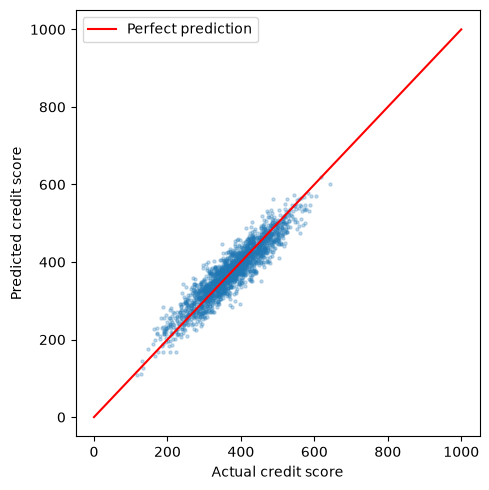

In [36]:
plt.figure(figsize=(5, 5))
plt.scatter(y_regression_test, linear_predictions, s=5, alpha=0.25)
plt.plot([0, 1000], [0, 1000], color="red", label="Perfect prediction")
plt.xlabel("Actual credit score")
plt.ylabel("Predicted credit score")
plt.legend()
plt.tight_layout()
plt.show()

**출력 읽기:** 점들이 빨간 대각선(완벽한 예측) 주변에 모여 있다. RMSE가 약 30인데, 데이터를 만들 때 넣은 잡음의 크기(표준편차 30)와 같다. 잡음은 어떤 모델로도 예측할 수 없으므로, 선형 회귀가 줄일 수 있는 오차는 거의 다 줄였다는 뜻이다.

### 10-1. 과대적합 확인 — Train과 Test 오차 비교

**과대적합**은 모델이 학습 데이터의 잡음까지 외워서, 학습 데이터에서는 잘 맞는데 새 데이터에서는 덜 맞는 상태다. 그래서 Train 오차와 Test 오차의 차이로 확인한다.

In [37]:
linear_train_rmse = np.sqrt(mean_squared_error(y_regression_train, linear_pipeline.predict(X_train)))
linear_test_rmse = np.sqrt(mean_squared_error(y_regression_test, linear_predictions))
print("선형 회귀 Train RMSE:", linear_train_rmse)
print("선형 회귀 Test RMSE:", linear_test_rmse)

선형 회귀 Train RMSE: 29.54730248578239
선형 회귀 Test RMSE: 30.1256653152408


**출력 읽기:** 두 오차가 거의 같다. 변수 6개에 학습 고객 8,000명이면, 선형 모델이 잡음을 외울 여지가 거의 없다. 이 데이터의 선형 회귀는 과대적합이 아니다. 10-3의 규제는 과대적합을 줄이는 대표적인 방법이므로, 여기서는 성능을 크게 바꾸지 못할 것이라고 예상할 수 있다.

### 10-2. 선형 회귀가 배운 것 — 가중치(계수)

선형 회귀는 이런 식으로 점수를 예측한다.

> 예측 점수 = 절편 + w₁ × 나이 + w₂ × 소득 + … + w₆ × 연체 횟수

w를 **계수**(coefficient)라고 부르고, **가중치**(weight)라고 불러도 같은 뜻이다. "그 변수가 1만큼 커질 때 예측 점수가 몇 점 바뀌는가"다. scikit-learn에서는 `coef_`에 저장된다. **절편**(intercept)은 모든 변수가 0일 때의 값인데, 여기서는 표준화를 했으므로 "모든 변수가 평균인 고객"의 예측 점수가 된다.

표준화한 입력으로 배웠으므로 w는 "1 **표준편차**당 몇 점"이다. 표준편차로 나누면 원래 단위(1만원, 1회 등)당 효과로 되돌릴 수 있다. 1장의 정답 공식과 비교한다.

In [38]:
linear_weights = linear_pipeline.named_steps["model"].coef_
feature_std = linear_pipeline.named_steps["preprocessing"].named_steps["scaler"].scale_

weight_table = pd.DataFrame({
    "weight_per_1_std": linear_weights,
    "feature_std": feature_std,
    "weight_per_1_unit": linear_weights / feature_std,
    "true_formula": [0, 0.03, 0, -100, 0, -50],
}, index=feature_columns)
display(weight_table)
print("절편(모든 변수가 평균인 고객의 예측 점수):", linear_pipeline.named_steps["model"].intercept_)

,weight_per_1_std,feature_std,weight_per_1_unit,true_formula
age,-0.2293,14.3681,-0.0160,0.00
annual_income,58.0145,1941.1620,0.0299,0.03
spending_score,-0.1689,28.7575,-0.0059,0.00
debt_ratio,-28.7834,0.2877,-100.0428,-100.00
credit_card_count,0.1705,2.5730,0.0663,0.00
overdue_count_6m,-35.8709,0.7169,-50.0353,-50.00


절편(모든 변수가 평균인 고객의 예측 점수): 375.321125


**출력 읽기:** `weight_per_1_unit` 열을 `true_formula`와 비교한다. 소득 1만원당 +0.03점, 부채 비율 1당 −100점, 연체 1회당 −50점이다. 모델은 공식을 본 적이 없는데 데이터만 보고 거의 정확히 찾아냈다.

잡음 변수(나이·소비 점수·카드 수)의 가중치는 0에 가깝지만 **정확히 0은 아니다**. 8,000명이라는 한정된 표본에서는 우연히 신용 점수와 아주 약하게 같이 움직이는 부분이 생기고, 모델은 그것이 우연인지 알 수 없어서 조금씩 가중치를 준다. 이 작은 가중치를 0으로 눌러 주는 것이 다음 절의 규제다.

**선형 회귀는 이 w와 절편을 어떻게 구했나.** 기준은 하나다. 고객마다 오차(실제 − 예측)를 제곱해 모두 더한 **오차 제곱의 합**이 가장 작아지는 w와 절편을 고른다. 변수가 하나라면, 점들 사이에 직선을 긋되 각 점에서 직선까지 세로 거리의 제곱 합이 최소인 직선을 찾는 일이다. 위에서 R²를 계산할 때 쓴 B가 바로 이 값이다.

로지스틱 회귀(5-2)는 반복해서 조금씩 옮겨 갔지만, 선형 회귀는 반복이 필요 없다. 오차 제곱의 합은 w에 대한 이차식이라서 그릇 모양이고, 가장 낮은 지점이 하나뿐이어서 식을 풀어 한 번에 구할 수 있기 때문이다(**최소제곱법**). 같은 해를 직접 구해 본다. 절편도 함께 구하도록 값이 항상 1인 열을 하나 붙인다.

In [39]:
prepared_train = linear_pipeline.named_steps["preprocessing"].transform(X_train)
design_matrix = np.column_stack([np.ones(len(prepared_train)), prepared_train])   # 첫 열 1은 절편 몫
y_train_scores = y_regression_train.to_numpy()

by_hand_solution = np.linalg.lstsq(design_matrix, y_train_scores, rcond=None)[0]   # 최소제곱 해
fitted_model = linear_pipeline.named_steps["model"]
display(pd.DataFrame({
    "least squares (by hand)": by_hand_solution,
    "LinearRegression": np.append(fitted_model.intercept_, fitted_model.coef_),
}, index=["intercept"] + feature_columns))

def sum_squared_errors(intercept_and_weights):
    return np.sum((y_train_scores - design_matrix @ intercept_and_weights) ** 2)

moved_solution = by_hand_solution.copy()
moved_solution[feature_columns.index("annual_income") + 1] += 5   # 소득의 w만 5점 올려 본다
print("구한 w의 오차 제곱 합:", sum_squared_errors(by_hand_solution))
print("소득 w를 5 올린 경우:   ", sum_squared_errors(moved_solution))

,least squares (by hand),LinearRegression
intercept,375.3211,375.3211
age,-0.2293,-0.2293
annual_income,58.0145,58.0145
spending_score,-0.1689,-0.1689
debt_ratio,-28.7834,-28.7834
credit_card_count,0.1705,0.1705
overdue_count_6m,-35.8709,-35.8709


구한 w의 오차 제곱 합: 6984344.673490577
소득 w를 5 올린 경우:    7184344.673490578


**출력 읽기:** 직접 푼 값이 `LinearRegression`이 저장한 `coef_`·`intercept_`와 같다. 이 모델의 `fit`은 이 계산을 하는 것이다. 마지막 두 줄은 구한 값에서 w 하나만 바꿔도 오차 제곱의 합이 커진다는 것을 보여 준다. 구한 값이 최저점이라는 뜻이다.

### 10-3. 규제 — Ridge와 Lasso

**Ridge와 Lasso는 새로운 종류의 모델이 아니라, 선형 회귀에 벌점을 더한 변형이다.** 예측하는 식은 위의 선형 회귀와 똑같다. 다른 것은 가중치를 고르는 기준(**손실 함수**)뿐이다.

| | 가중치를 고르는 기준 (이 값이 가장 작아지는 가중치를 찾는다) |
| --- | --- |
| 선형 회귀 | 오차 제곱의 합 |
| Ridge (L2 규제) | 오차 제곱의 합 **+ α × (w₁² + w₂² + … )** |
| Lasso (L1 규제) | 오차 제곱 평균의 절반 **+ α × (\|w₁\| + \|w₂\| + … )** |

가중치를 키우면 오차는 줄지만 벌점이 늘어난다. 그래서 모델은 "오차를 충분히 줄여 주는 변수"에만 큰 가중치를 주고, 도움이 적은 변수의 가중치는 줄인다. **α(Alpha)**는 벌점의 세기다. 0이면 선형 회귀와 같고, 클수록 가중치를 강하게 누른다. scikit-learn에서는 `Ridge`, `Lasso`라는 별도 클래스로 제공해서 흔히 "Ridge 모델"이라고도 부른다. 정확히는 "L2 규제를 건 선형 회귀", "L1 규제를 건 선형 회귀"다.

벌점 모양의 차이 때문에 결과가 다르다.

- **Lasso:** 가중치를 정확히 0으로 만들 수 있다. 그 변수를 아예 안 쓰게 된다.
- **Ridge:** 가중치를 줄이기만 하고 0으로 만들지는 않는다.

Lasso는 이 노트북만의 모델이 아니라 통계와 머신러닝에서 널리 쓰는 표준 기법(1996년 제안)이다. 다른 곳의 Lasso도 같은 모델이고, 결과가 다른 것은 데이터와 α, 전처리가 다르기 때문이다. 다만 α의 숫자는 라이브러리마다 오차를 합으로 쓸지 평균으로 쓸지가 달라서 그대로 옮겨 쓸 수 없다. 위 표에서도 scikit-learn의 Ridge는 오차 제곱의 **합**, Lasso는 **평균**의 절반을 쓴다.

Lasso가 0을 만드는 이유는 벌점의 모양이다. `|w|` 벌점은 w가 아무리 작아도 줄일 때마다 같은 만큼(α) 이득이 생긴다. 그 변수가 오차를 줄여 주는 효과가 α보다 작으면, 가중치를 0까지 내리는 편이 이득이다. 반면 `w²` 벌점은 w가 0에 가까울수록 이득이 사라져서 0에 닿지 못한다. 이 계산은 10-4에서 숫자로 확인한다.

α 다섯 개로 두 모델을 학습해 가중치가 어떻게 변하는지 본다.

In [40]:
from sklearn.linear_model import Ridge, Lasso

alpha_values = [0.01, 0.1, 1, 10, 100]
ridge_coefficients = []
lasso_coefficients = []

for alpha in alpha_values:
    ridge_pipeline = Pipeline([
        ("preprocessing", clone(numeric_preprocessor)),
        ("model", Ridge(alpha=alpha)),
    ])
    ridge_pipeline.fit(X_train, y_regression_train)
    ridge_coefficients.append(ridge_pipeline.named_steps["model"].coef_)

    lasso_pipeline = Pipeline([
        ("preprocessing", clone(numeric_preprocessor)),
        ("model", Lasso(alpha=alpha, max_iter=50_000)),
    ])
    lasso_pipeline.fit(X_train, y_regression_train)
    lasso_coefficients.append(lasso_pipeline.named_steps["model"].coef_)

ridge_coefficient_table = pd.DataFrame(ridge_coefficients, index=alpha_values, columns=feature_columns)
lasso_coefficient_table = pd.DataFrame(lasso_coefficients, index=alpha_values, columns=feature_columns)
lasso_coefficient_table.index.name = "alpha"
display(lasso_coefficient_table)

,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m
alpha,,,,,,
0.01,-0.2196,58.0048,-0.1588,-28.7729,0.1607,-35.8611
0.10,-0.1325,57.9179,-0.0674,-28.6786,0.0725,-35.7729
1.00,-0.0000,57.0237,-0.0000,-27.7773,0.0000,-34.8679
10.00,-0.0000,48.0446,0.0000,-18.8133,0.0000,-25.7900
100.00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


**출력 읽기 (Lasso 표):** 한 행이 α 하나다.

- α = 0.01, 0.1에서는 잡음 변수의 가중치도 아직 0이 아니다(나이 −0.22, −0.13). α와 상관없이 0이 되는 것이 아니다.
- α = 1에서 나이·소비 점수·카드 수의 가중치가 0이 된다(`-0.0000`은 아주 작은 음수 계산 오차를 표시한 것으로, 0과 같다). 1장의 잡음 변수 세 개다. 모델이 이 변수들이 잡음임을 이해한 것이 아니다. 선형 회귀에서 이 세 변수의 가중치가 0.17~0.23점(표준편차당)으로 α = 1보다 작았기 때문에 0까지 내려간 것이다. 같은 이유로 효과가 작은 진짜 변수가 있었다면 그것도 0이 된다.
- α = 10에서는 신호 변수의 가중치까지 줄어들고, α = 100에서는 모두 0이 되어 평균 모델과 같아진다.

아래 그래프로 두 방법을 비교한다. Ridge는 α가 100이어도 거의 변하지 않으므로(위 계산의 n ÷ (n + α)는 10-4에서 설명한다), 그래프에서는 두 모델의 α 범위를 다르게 잡는다. 윗줄은 6개 변수 전체이고, 아랫줄은 값이 작은 잡음 변수 세 개만 확대한 것이다.

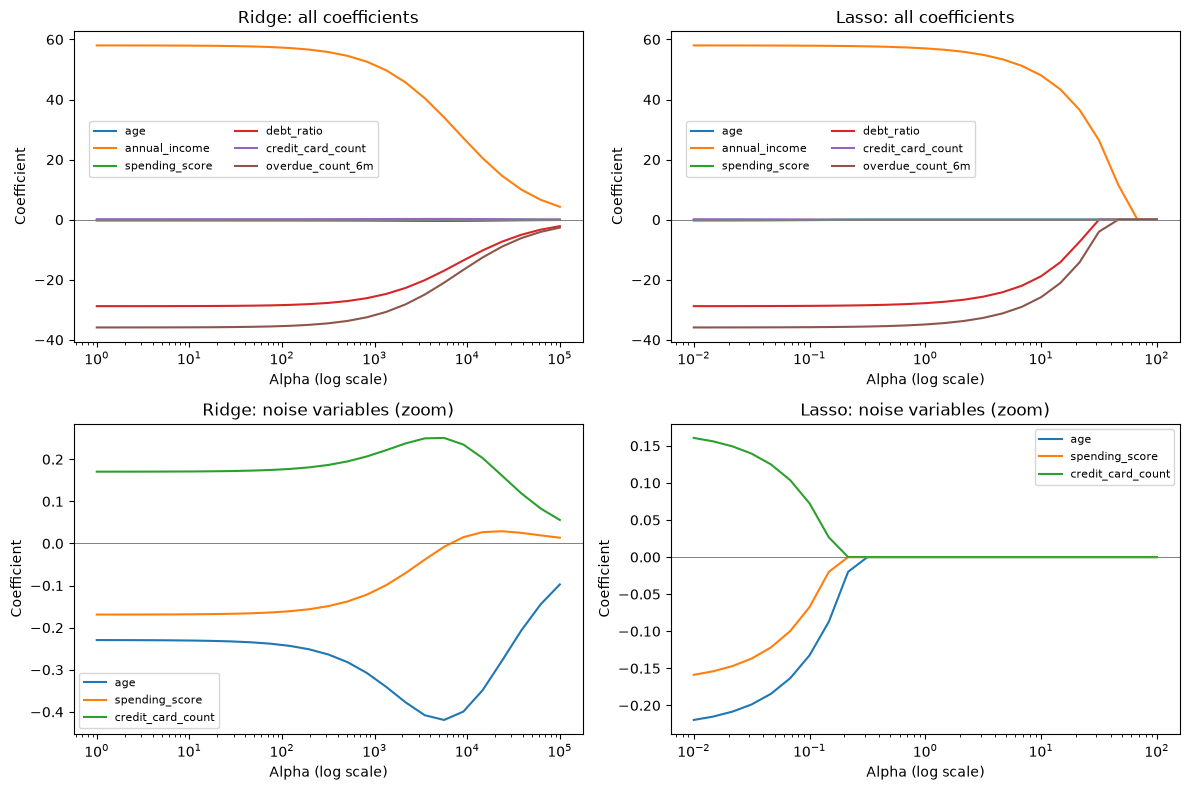

In [41]:
ridge_path_alphas = np.logspace(0, 5, 25)    # Ridge는 알파가 수천은 되어야 눈에 띄게 줄어든다
lasso_path_alphas = np.logspace(-2, 2, 25)

def coefficient_path(model_class, alphas):
    path_rows = []
    for alpha in alphas:
        path_pipeline = Pipeline([
            ("preprocessing", clone(numeric_preprocessor)),
            ("model", model_class(alpha=alpha, max_iter=50_000)),
        ])
        path_pipeline.fit(X_train, y_regression_train)
        path_rows.append(path_pipeline.named_steps["model"].coef_)
    return pd.DataFrame(path_rows, index=alphas, columns=feature_columns)

ridge_path = coefficient_path(Ridge, ridge_path_alphas)
lasso_path = coefficient_path(Lasso, lasso_path_alphas)
noise_columns = ["age", "spending_score", "credit_card_count"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
ridge_path.plot(ax=axes[0, 0], logx=True, title="Ridge: all coefficients")
lasso_path.plot(ax=axes[0, 1], logx=True, title="Lasso: all coefficients")
ridge_path[noise_columns].plot(ax=axes[1, 0], logx=True, title="Ridge: noise variables (zoom)")
lasso_path[noise_columns].plot(ax=axes[1, 1], logx=True, title="Lasso: noise variables (zoom)")
for axis in axes.ravel():
    axis.set_xlabel("Alpha (log scale)")
    axis.set_ylabel("Coefficient")
    axis.axhline(0, color="gray", linewidth=0.7)
for axis in axes[0]:
    axis.legend(fontsize=8, ncol=2, loc="center left", bbox_to_anchor=(0.02, 0.62))
for axis in axes[1]:
    axis.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()

**출력 읽기:**

- **윗줄:** Lasso는 α가 커지면 가중치가 하나씩 0으로 떨어진다. Ridge는 α가 수천을 넘어야 눈에 띄게 줄어들고, 큰 신호 변수들이 비슷한 비율로 함께 줄어든다. Ridge는 α가 10만이어도 소득의 가중치가 약 4.3으로 0이 아니다.
- **아랫줄(확대):** Lasso의 잡음 변수 세 개는 α가 0.3 안팎을 넘는 곳에서 0에 닿은 뒤 그대로 붙어 있다. Ridge의 잡음 변수는 0에 닿지 않고, 오히려 α가 수천일 때까지는 조금 커졌다가(나이 −0.23에서 −0.40까지) 줄어든다. 큰 신호 변수의 가중치가 눌리는 동안 잡음 변수가 남은 오차의 우연한 흐름을 더 따라가기 때문으로 보인다.
- 두 모델의 α는 범위가 다르다. 같은 α에서의 세기를 비교하는 그래프가 아니다.

### 10-4. 작동 방식을 숫자로 확인하기

이 데이터의 6개 변수는 서로 거의 상관없이 만들어졌다. 이런 경우 두 규제의 효과를 간단한 계산으로 정확히 설명할 수 있다.

- **Lasso:** 각 가중치의 크기에서 **α만큼 빼고, 0에 닿으면 0에서 멈춘다.**
- **Ridge:** 각 가중치에 **n ÷ (n + α)를 곱한다** (n = 학습 고객 수 8,000).

먼저 Lasso다. 10-2의 선형 회귀 가중치에 "α 빼기"를 적용해 실제 Lasso 결과와 비교한다.

In [42]:
lasso_by_shortcut = []
for alpha in alpha_values:
    shrunk_size = np.maximum(np.abs(linear_weights) - alpha, 0)   # 크기에서 alpha를 빼되 0 아래로는 내려가지 않음
    lasso_by_shortcut.append(np.sign(linear_weights) * shrunk_size)  # 원래 부호(+/-)를 붙임

lasso_shortcut_table = pd.DataFrame(lasso_by_shortcut, index=alpha_values, columns=feature_columns)
lasso_shortcut_table.index.name = "alpha"
display(lasso_shortcut_table)
print("실제 Lasso 가중치와의 최대 차이:", np.abs(lasso_shortcut_table - lasso_coefficient_table).to_numpy().max())

,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m
alpha,,,,,,
0.01,-0.2193,58.0045,-0.1589,-28.7734,0.1605,-35.8609
0.10,-0.1293,57.9145,-0.0689,-28.6834,0.0705,-35.7709
1.00,-0.0000,57.0145,-0.0000,-27.7834,0.0000,-34.8709
10.00,-0.0000,48.0145,-0.0000,-18.7834,0.0000,-25.8709
100.00,-0.0000,0.0000,-0.0000,-0.0000,0.0000,-0.0000


실제 Lasso 가중치와의 최대 차이: 0.08086042855746811


**출력 읽기:** 간단한 계산이 실제 Lasso 표와 거의 같다. 이제 질문에 답할 수 있다.

- **나이는 왜 α = 1에서 0이 됐나?** 선형 회귀에서 나이의 가중치 크기는 약 0.23이다. α = 0.1이면 0.23 − 0.1 = 0.13이 남고, α = 1이면 0.23 − 1이 음수가 되므로 0에서 멈춘다.
- **소득은 왜 α = 100에서야 0이 됐나?** 소득의 가중치는 약 58이다. α가 58보다 커져야 0이 된다.
- **왜 정확히 0이 되나?** Lasso의 벌점 α × |w|는 w가 작아져도 같은 힘(α)으로 0 쪽으로 민다. 그래서 오차를 줄이는 힘이 α보다 약한 작은 가중치는 0까지 밀려난다.

다음은 Ridge다. Ridge의 벌점 α × w²는 w가 작아질수록 미는 힘도 작아진다(w가 절반이 되면 힘도 절반). 그래서 0에 가까워질 뿐 정확히 0에 닿지 않는다. "n ÷ (n + α) 곱하기"를 소득 가중치로 확인하고, α를 훨씬 크게도 키워 본다.

In [43]:
n_train = len(X_train)
ridge_rows = []
for alpha in [1, 100, 1_000, 8_000, 80_000]:
    ridge_model = Pipeline([
        ("preprocessing", clone(numeric_preprocessor)),
        ("model", Ridge(alpha=alpha)),
    ])
    ridge_model.fit(X_train, y_regression_train)
    income_weight = ridge_model.named_steps["model"].coef_[income_column]
    ridge_rows.append({
        "alpha": alpha,
        "income_weight": income_weight,
        "ratio_to_linear": income_weight / linear_weights[income_column],
        "shortcut_n/(n+alpha)": n_train / (n_train + alpha),
    })
display(pd.DataFrame(ridge_rows))

,alpha,income_weight,ratio_to_linear,shortcut_n/(n+alpha)
0,1,58.0072,0.9999,0.9999
1,100,57.2983,0.9877,0.9877
2,1000,51.5692,0.8889,0.8889
3,8000,29.0126,0.5001,0.5000
4,80000,5.2770,0.0910,0.0909


**출력 읽기:** 실제 비율과 n ÷ (n + α)가 거의 같다.

- **왜 Ridge 그래프는 변화가 없어 보였나?** α = 100이면 8000 ÷ 8100 = 0.988, 즉 가중치를 1.2%만 줄인다. 그래프에서 보이지 않을 만큼 작다.
- α가 n과 같은 8,000이 되어야 가중치가 절반이 된다. 80,000이면 0.09배로 크게 줄지만 여전히 0은 아니다.
- 같은 α라도 Lasso는 크기에서 α를 **빼고**, Ridge는 n ÷ (n + α)를 **곱한다**. 그래서 두 모델의 α 숫자를 그대로 비교하지 않는다.

### 10-5. Alpha 고르기 — 8장의 교차검증 사용

Alpha를 Test나 그래프를 보고 고르지 않는다. **GridSearchCV**는 후보마다 8장의 교차검증을 실행해 평균 점수가 가장 좋은 후보를 고르는 도구다. 마지막에 그 설정으로 Train 전체를 다시 학습한다.

`model__alpha`는 Pipeline 안 "model" 단계의 alpha라는 뜻이다. 점수 이름 `neg_root_mean_squared_error`는 RMSE에 마이너스를 붙인 것이다. 이 도구는 "점수가 클수록 좋다"고 가정하기 때문이다.

In [44]:
from sklearn.model_selection import GridSearchCV, KFold

regression_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_search = GridSearchCV(
    Pipeline([("preprocessing", clone(numeric_preprocessor)), ("model", Ridge())]),
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error", cv=regression_cv,
)
ridge_search.fit(X_train, y_regression_train)

lasso_search = GridSearchCV(
    Pipeline([("preprocessing", clone(numeric_preprocessor)),
              ("model", Lasso(max_iter=50_000))]),
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error", cv=regression_cv,
)
lasso_search.fit(X_train, y_regression_train)

print("Ridge가 고른 Alpha:", ridge_search.best_params_["model__alpha"])
print("Lasso가 고른 Alpha:", lasso_search.best_params_["model__alpha"])
regression_rows.append(evaluate_regressor("Ridge (CV)", y_regression_test, ridge_search.predict(X_test)))
regression_rows.append(evaluate_regressor("Lasso (CV)", y_regression_test, lasso_search.predict(X_test)))
display(pd.DataFrame(regression_rows))

Ridge가 고른 Alpha: 1
Lasso가 고른 Alpha: 0.1


,model,mae,rmse,r2
0,Mean,64.7302,80.8737,-0.0004
1,Linear,23.9327,30.1257,0.8612
2,Ridge (CV),23.9328,30.1259,0.8612
3,Lasso (CV),23.9297,30.1284,0.8612


**출력 읽기:** 10-1에서 예상한 대로, 규제를 넣어도 Test 오차는 선형 회귀와 거의 같다. 줄일 과대적합이 없고, 쓸모없는 변수의 계수도 원래 작았기 때문이다. 이 데이터에서 규제의 쓸모는 성능보다 "어떤 변수가 필요 없는지 알려준다"(10-3의 Lasso 표)는 데 있다.

**확인 질문:** Lasso의 계수가 모두 0이 되면 어떤 예측이 남을까?
<details><summary>답 확인</summary>계수가 모두 0이면 입력과 상관없이 절편(Train 평균 점수)만 남는다. 모든 고객에게 같은 점수를 주므로 평균 모델과 같아진다. Alpha가 클수록 좋은 것이 아니다.</details>

### 10-6. 같은 고객, 두 가지 예측 — 회귀와 분류 비교

같은 입력으로 만든 두 모델을 한 고객씩 나란히 놓는다. 1장에서 본 대로 연체 라벨은 "신용 점수가 하위 15% 기준점보다 낮은가"로 만들어졌다. 기준점 근처 고객을 골라 본다.

In [45]:
score_threshold = customers["credit_score"].quantile(0.15)   # 데이터 생성에 쓰인 연체 기준점
print("연체 기준점(하위 15% 점수):", score_threshold)

side_by_side = pd.DataFrame({
    "actual_score": y_regression_test.to_numpy(),
    "predicted_score": linear_predictions,
    "actual_overdue": y_test_array,
    "overdue_probability": pipeline_probabilities,
})
is_near = (side_by_side["actual_score"] - score_threshold).abs().to_numpy() <= 20
print("기준점 ±20점 안의 Test 고객:", is_near.sum(), "/", len(side_by_side))
display(side_by_side[is_near].head(8))

logistic_wrong = logistic_pipeline.predict(X_test) != y_test_array
print("기준점 근처 고객의 분류 오류율:", logistic_wrong[is_near].mean())
print("나머지 고객의 분류 오류율:", logistic_wrong[~is_near].mean())

연체 기준점(하위 15% 점수): 292.0
기준점 ±20점 안의 Test 고객: 244 / 2000


,actual_score,predicted_score,actual_overdue,overdue_probability
0,286.0,322.1864,1,0.1194
23,277.0,278.4475,1,0.4289
25,303.0,338.9280,0,0.0666
29,299.0,311.1876,0,0.1629
49,306.0,334.4918,0,0.0880
55,297.0,277.1892,0,0.4812
56,291.0,307.2753,1,0.2316
62,291.0,339.2287,1,0.0702


기준점 근처 고객의 분류 오류율: 0.3360655737704918
나머지 고객의 분류 오류율: 0.043849658314350795


**출력 읽기:** 회귀 쪽에서 20~30점 오차는 RMSE 수준의 평범한 오차다. 하지만 기준점 근처 고객은 점수가 조금만 달라도 정상/연체가 바뀐다. 게다가 기준점 아래 고객도 80%만 연체로 표시됐다. 그래서 분류 모델은 이 구간에서 훨씬 자주 틀린다(오류율 약 34% vs 나머지 약 4%).

| | 회귀 (신용 점수) | 분류 (연체 여부) |
| --- | --- | --- |
| 출력 | 숫자 하나 (점) | 연체 확률 → 임계값으로 0/1 |
| 평가 | 얼마나 가깝나: MAE·RMSE(점), R² | 맞았나 틀렸나: 혼동행렬, Precision·Recall·F1, 순서: AUC |
| 이 데이터에서 어려운 점 | 잡음 30점은 줄일 수 없다 | 연체자가 12%뿐이고, 기준점 근처가 헷갈린다 |

**확인 질문:** 신용 점수를 예측하는 회귀 모델이 있으니 "예측 점수 < 기준점이면 연체"로 분류하면 되지 않을까? 무엇이 아쉬울까?
<details><summary>답 확인</summary>가능하다. 이 데이터에서는 오히려 5장의 0.5 기준 로지스틱 회귀보다 F1이 높게 나온다. 연체 라벨 자체를 점수로 만들었기 때문이다. 실제 데이터에서는 연체가 점수 하나로 정해지지 않는다. 또 회귀는 모든 점수 구간의 오차를 똑같이 줄이려 하고, 분류는 정상/연체를 가르는 경계에 집중한다. 그리고 분류 모델은 "얼마나 위험한가"를 확률로 주므로 6장처럼 임계값을 업무 목적에 맞게 조절할 수 있다. 무엇을 예측하고 어떻게 쓸지에 따라 문제 유형과 지표를 고른다.</details>

## 정리

| 장 | 해 본 것 | 기억할 것 |
| --- | --- | --- |
| 1~2 | 입력/정답 구분, Train/Test 분할 | 정답은 입력에 넣지 않는다. Test는 마지막 채점에만 쓴다 |
| 3~4 | 규칙 베이스라인, 혼동행렬 | Accuracy만 보면 속는다. Precision·Recall·F1을 함께 본다 |
| 5~6 | 로지스틱 회귀, 임계값, ROC-AUC | 판정 = 확률 + 임계값. AUC는 임계값과 무관한 순서 능력이다 |
| 7~8 | Pipeline, 교차검증 | 전처리 기준도 학습의 일부다. 설정 비교는 Train 안에서 한다 |
| 9 | class_weight, SMOTE | 효과는 주로 판정 기준을 연체 쪽으로 옮기는 것 |
| 10 | 선형 회귀와 가중치, 과대적합 확인, Ridge·Lasso, 회귀와 분류 비교 | 회귀는 오차 크기(MAE·RMSE)와 R²로 평가한다. Ridge·Lasso는 선형 회귀에 벌점을 더한 것으로, Lasso는 가중치에서 α를 빼서 작은 가중치를 0으로, Ridge는 비율로 줄여 0 근처까지만 보낸다. 같은 입력이라도 문제 유형에 따라 출력·지표·해석이 다르다 |

여기까지 Test는 각 모델을 채점할 때만 썼다. 다만 여러 모델의 Test 점수를 계속 비교해 하나를 고르면, 그것도 Test에 맞춘 선택이 된다. 최종 모델은 교차검증 점수로 고른다.

---

# 부록 — 더 알아보기

본편을 이해했다면 이어서 본다. 각 부록은 본편의 결과를 사용하므로 본편을 먼저 실행해야 한다. A와 B는 이어서 실행한다.

## A. 앙상블 — Random Forest와 GridSearchCV

### A-1. 재료: 결정 나무

**결정 나무**(decision tree)는 "소득이 ○○ 이하인가?" 같은 예/아니오 질문을 차례로 던져 고객을 나누는 모델이다. 3장의 if문 규칙과 모양이 같지만, **어떤 변수로 어떤 기준값에서 나눌지를 사람이 아니라 데이터에서 배운다.**

**질문을 고르는 방법:** 질문은 고객을 두 묶음으로 나눈다. 좋은 질문은 각 묶음이 연체 또는 정상 한쪽으로 쏠리게(**순수하게**) 만드는 질문이다. 순수한 정도는 **지니 불순도**로 잰다.

> 지니 불순도 = 1 − (연체 비율)² − (정상 비율)²

한 묶음이 전부 정상이면 0, 반반이면 0.5로 가장 높다. 학습은 모든 변수와 가능한 모든 기준값을 하나씩 시험해서, 나눈 두 묶음의 불순도(고객 수로 가중 평균)가 가장 낮아지는 질문을 고른다. 그다음 나뉜 묶음마다 같은 일을 반복하고, 정해 둔 깊이(`max_depth`)에서 멈춘다. 예측은 고객이 도착한 마지막 칸에서 다수인 쪽이다. 아래에서 첫 질문을 직접 찾아본다.

In [46]:
from sklearn.tree import DecisionTreeClassifier

def gini(positive_count, total_count):
    positive_rate = positive_count / total_count
    return 1 - positive_rate ** 2 - (1 - positive_rate) ** 2

train_labels = y_classification_train.to_numpy()
print("나누기 전 불순도:", gini(train_labels.sum(), len(train_labels)))

best_split_rows = []
for feature in feature_columns:
    values = X_train[feature].to_numpy()
    order = np.argsort(values, kind="stable")                  # 값이 작은 고객부터 세운다
    sorted_values, sorted_labels = values[order], train_labels[order]
    left_total = np.arange(1, len(sorted_labels))              # i번째 앞에서 자르면 왼쪽 고객 수
    left_positive = np.cumsum(sorted_labels)[:-1]              # 왼쪽의 연체자 수
    right_total = len(sorted_labels) - left_total
    right_positive = sorted_labels.sum() - left_positive
    after_split = (left_total * gini(left_positive, left_total)
                   + right_total * gini(right_positive, right_total)) / len(sorted_labels)
    after_split = np.where(sorted_values[:-1] != sorted_values[1:], after_split, np.inf)  # 같은 값 사이는 못 자른다
    best = after_split.argmin()
    best_split_rows.append({"feature": feature,
                            "best_threshold": (sorted_values[best] + sorted_values[best + 1]) / 2,
                            "impurity_after_split": after_split[best]})
display(pd.DataFrame(best_split_rows).set_index("feature"))

stump = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE).fit(X_train, y_classification_train)
print("scikit-learn이 고른 첫 질문:", feature_columns[stump.tree_.feature[0]], "<=", stump.tree_.threshold[0])

나누기 전 불순도: 0.21138996875000005


,best_threshold,impurity_after_split
feature,,
age,20.500,0.2113
annual_income,3316.500,0.1788
spending_score,85.500,0.2113
debt_ratio,0.545,0.2026
credit_card_count,1.500,0.2113
overdue_count_6m,0.500,0.1961


scikit-learn이 고른 첫 질문: annual_income <= 3316.5


**출력 읽기:** 변수마다 가장 좋은 기준값과 그때의 불순도가 나온다. 소득이 불순도를 가장 많이 낮추고(나누기 전 약 0.211에서 약 0.179), 연체 횟수와 부채 비율이 뒤를 잇는다. 잡음 변수는 거의 줄이지 못한다(0.211 근처). scikit-learn이 고른 첫 질문도 소득 3316.5 이하인가로, 직접 찾은 결과와 같다. 이제 질문 두 번(깊이 2)까지만 하는 작은 나무를 학습해 본다. 나무는 크기 비교만 하므로 표준화가 필요 없어 원본 값으로 학습한다.

In [47]:
from sklearn.tree import DecisionTreeClassifier, export_text

small_tree = DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=RANDOM_STATE)
small_tree.fit(X_train, y_classification_train)
print(export_text(small_tree, feature_names=feature_columns))

|--- annual_income <= 4310.50
|   |--- overdue_count_6m <= 0.50
|   |   |--- class: 1
|   |--- overdue_count_6m >  0.50
|   |   |--- class: 1
|--- annual_income >  4310.50
|   |--- overdue_count_6m <= 1.50
|   |   |--- class: 0
|   |--- overdue_count_6m >  1.50
|   |   |--- class: 1



**출력 읽기:** 들여쓰기 한 단계가 질문 하나이고, `class: 1`로 끝나는 경로가 연체 판정이다. 이 나무는 "소득이 4,310.5 이하이면 연체, 그보다 많아도 최근 연체가 2회 이상이면 연체"라고 판정한다. 3장의 규칙도 소득과 연체 횟수를 썼지만 기준값(소득 3,000 등)은 사람이 골랐다. 나무는 6개 변수와 가능한 모든 기준값 중에서 연체자와 정상 고객을 가장 잘 가르는 질문을 데이터에서 찾았다. 잡음 변수(나이·소비 점수·카드 수)는 고르지 않았다. (`class_weight="balanced"`로 연체자에게 더 큰 무게를 줬기 때문에 연체 판정이 넉넉한 편이다.)

나무는 깊게 키울수록 Train을 더 잘게 나눠 외운다. 그래서 학습 데이터가 조금만 달라져도 모양이 크게 바뀐다(부록 D의 과대적합). 이 약점을 여러 모델을 합쳐 보완하는 방법이 앙상블이다.

### A-2. 앙상블 — 여러 모델의 판단을 합치기

**앙상블**(ensemble)은 여러 모델의 예측을 합쳐 하나의 예측을 만드는 방법이다. 결정 나무를 재료로 하는 대표적인 방식이 두 가지다.

| | **배깅(Bagging)** — 예: Random Forest | **부스팅(Boosting)** — 예: Gradient Boosting, XGBoost |
| --- | --- | --- |
| 나무를 만드는 순서 | 서로 독립적으로, 동시에 | 하나씩 차례로 |
| 나무끼리의 차이 | 나무마다 Train에서 무작위로 다시 뽑은 고객으로 학습하고, 질문마다 변수 일부만 후보로 써서 서로 다른 나무가 된다 | 다음 나무는 앞의 나무들이 **틀린 부분**을 고치도록 학습한다 |
| 합치는 방법 | 나무들의 확률을 평균(다수결) | 나무들의 예측을 차례로 더함 |
| 주로 줄이는 것 | 깊은 나무 한 그루의 흔들림(분산) | 얕은 나무 한 그루의 단순함(편향) |

이 노트북에서는 **Random Forest(RF)**를 실습한다. 서로 조금씩 다른 나무 수백 그루가 각자 판단하고, 그 평균을 최종 확률로 쓴다. 한 그루가 우연히 틀려도 다른 나무들이 바로잡는다.

먼저 기본 설정의 RF를 교차검증으로 평가한다.

In [48]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterGrid

default_forest = Pipeline([
    ("preprocessing", clone(numeric_preprocessor)),
    ("model", RandomForestClassifier(class_weight="balanced",
                                      random_state=RANDOM_STATE, n_jobs=2)),
])
default_forest_cv = cross_val_score(default_forest, X_train, y_classification_train,
                                    scoring="f1", cv=classification_cv)
default_forest.fit(X_train, y_classification_train)
print("기본 RF 교차검증 F1:", default_forest_cv.mean())

기본 RF 교차검증 F1: 0.6576629296774489


### A-3. GridSearchCV — 하이퍼파라미터 탐색

**하이퍼파라미터**는 학습 전에 사람이 정하는 설정값이고, **파라미터**는 학습이 데이터에서 정하는 값이다.

| 구분 | 누가 정하나 | 이 노트북의 예 |
| --- | --- | --- |
| 하이퍼파라미터 | 사람이 학습 **전에** | RF의 나무 수(`n_estimators`)·최대 깊이(`max_depth`)·마지막 칸의 최소 고객 수(`min_samples_leaf`), 10장의 α, `class_weight` |
| 파라미터 | 학습(`fit`)이 데이터에서 | 10-2의 가중치와 절편, A-1의 질문과 기준값 |

**GridSearchCV**는 하이퍼파라미터의 좋은 값을 찾아 주는 도구다. 다만 후보값과 채점 기준(F1 등)은 사람이 정하고, 도구는 그 후보들을 전부 시험해 점수가 가장 높은 것을 고를 뿐이다. 후보 밖의 값은 시험하지 않는다. 이름 그대로 동작한다.

1. **Grid(격자):** 하이퍼파라미터마다 후보값을 적으면, 모든 조합을 만든다. 아래는 2 × 2 × 2 = 8가지다.
2. **CV(교차검증):** 조합마다 8장의 5-fold 교차검증을 한다. 8조합 × 5번 = 모델 40개를 학습한다.
3. 평균 점수가 가장 좋은 조합을 고르고, 그 조합으로 Train 전체를 한 번 더 학습한다(`best_estimator_`).

후보값은 사람이 정하므로, 격자 밖의 값은 찾지 못한다. 설명이 목적이라 여기서는 작은 격자를 쓴다.

In [49]:
forest_grid = {
    "model__n_estimators": [100, 200],     # 나무 수
    "model__max_depth": [8, 12],           # 나무 깊이 제한
    "model__min_samples_leaf": [1, 5],     # 마지막 칸에 남길 최소 고객 수
}
print("탐색 조합 수:", len(ParameterGrid(forest_grid)))
forest_search = GridSearchCV(clone(default_forest), param_grid=forest_grid,
                             scoring="f1", cv=classification_cv)
forest_search.fit(X_train, y_classification_train)
tuned_forest = forest_search.best_estimator_
print("고른 설정:", forest_search.best_params_)
print("고른 설정의 교차검증 F1:", forest_search.best_score_)

# 8개 조합 각각의 5-fold 평균 점수
search_results = pd.DataFrame(forest_search.cv_results_)[[
    "param_model__n_estimators", "param_model__max_depth", "param_model__min_samples_leaf",
    "mean_test_score", "std_test_score", "rank_test_score",
]].sort_values("rank_test_score")
display(search_results)

탐색 조합 수: 8


고른 설정: {'model__max_depth': 12, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
고른 설정의 교차검증 F1: 0.6670890061138851


,param_model__n_estimators,param_model__max_depth,param_model__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
5,200,12,1,0.6671,0.0239,1
4,100,12,1,0.6639,0.0230,2
6,100,12,5,0.6547,0.0257,3
7,200,12,5,0.6529,0.0259,4
1,200,8,1,0.6490,0.0182,5
0,100,8,1,0.6475,0.0187,6
2,100,8,5,0.6424,0.0230,7
3,200,8,5,0.6401,0.0247,8


**출력 읽기:** 한 행이 조합 하나이고, `mean_test_score`가 5개 검증 묶음의 평균 F1이다. 1등(`rank_test_score` = 1) 조합이 위의 "고른 설정"이다. 1등과 2등의 차이는 0.003 정도로, `std_test_score`(fold 사이의 흔들림, 약 0.02)보다 훨씬 작다. 그래서 정확한 순위보다 경향을 읽는 편이 낫다. 위쪽 네 줄은 모두 `max_depth` 12이고 아래쪽 네 줄은 모두 8이다. "나무를 더 깊게 허용하는 쪽이 이 데이터에서 일관되게 낫다"는 것이 이 탐색에서 믿을 만한 결론이다.

이제 기본 RF와 튜닝한 RF를 Test로 채점해 앞의 모델들과 비교한다.

In [50]:
classification_rows.append(evaluate_classifier("RF default", default_forest, X_test, y_classification_test))
classification_rows.append(evaluate_classifier("RF tuned", tuned_forest, X_test, y_classification_test))
display(pd.DataFrame(classification_rows))

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic,0.9205,0.7077,0.5750,0.6345,0.9505
1,Logistic + class_weight,0.8785,0.4965,0.8750,0.6335,0.9505
2,Logistic + SMOTE,0.8845,0.5109,0.8750,0.6452,0.9504
3,RF default,0.9105,0.6041,0.7375,0.6642,0.9388
4,RF tuned,0.8985,0.5539,0.7917,0.6518,0.9399


**출력 읽기:** 교차검증에서는 튜닝한 RF가 조금 나았는데, Test F1은 오히려 기본 RF보다 낮다. 두 차이(0.01 안팎)는 8장에서 본 fold 사이의 흔들림(표준편차 약 0.04)보다 작아서, 어느 쪽이 낫다고 말하기 어렵다. 또 F1은 RF가 높아도 ROC-AUC는 로지스틱 회귀가 더 높다. 이 데이터는 변수의 단순한 합으로 만들어졌기 때문에 선형 모델과 잘 맞는다. 앙상블이 언제나 이기는 것은 아니다.

## B. 승인·보류·거절 — 임계값 두 개 정하기

6장에서는 임계값 하나로 0/1을 나눴다. 대출 심사라면 기준을 두 개 두고 세 구간으로 나눌 수 있다.

- 연체 확률 < 보류 기준 → **승인**
- 보류 기준 ≤ 확률 < 거절 기준 → **보류**(사람이 심사)
- 확률 ≥ 거절 기준 → **거절**

기준은 Test가 아니라 Train으로 정한다. **OOF(out-of-fold) 예측**은 8장의 교차검증처럼 Train 고객 각자를, 그 고객을 빼고 학습한 모델로 예측한 확률이다. 이렇게 하면 Train으로도 "처음 보는 고객"에 대한 확률을 얻는다.

In [51]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

oof_probabilities = cross_val_predict(
    clone(tuned_forest), X_train, y_classification_train,
    cv=classification_cv, method="predict_proba",
)[:, 1]

# 가능한 모든 임계값에서의 Precision·Recall을 한 번에 계산한다.
# 마지막 Precision·Recall 값에는 대응하는 임계값이 없어서 [:-1]로 맞춘다.
precision_values, recall_values, thresholds = precision_recall_curve(
    y_classification_train, oof_probabilities)
precision_values = precision_values[:-1]
recall_values = recall_values[:-1]

f1_values = 2 * precision_values * recall_values / np.clip(precision_values + recall_values, 1e-12, None)
reject_threshold = thresholds[np.argmax(f1_values)]                # F1이 가장 높은 기준
hold_threshold = thresholds[recall_values >= 0.95].max()           # 연체자 95% 이상을 보류 이상으로 보내는 가장 높은 기준
hold_threshold = min(hold_threshold, reject_threshold)
print("보류 기준:", hold_threshold)
print("거절 기준:", reject_threshold)

보류 기준: 0.17332336138298451
거절 기준: 0.4926484065435953


In [52]:
test_risk_probabilities = tuned_forest.predict_proba(X_test)[:, 1]
policy_labels = np.full(len(X_test), "hold", dtype=object)
policy_labels[test_risk_probabilities < hold_threshold] = "approve"
policy_labels[test_risk_probabilities >= reject_threshold] = "reject"

policy_rows = []
for band_name in ["approve", "hold", "reject"]:
    band_mask = policy_labels == band_name
    customer_count = int(band_mask.sum())
    overdue_count = int(y_test_array[band_mask].sum())
    policy_rows.append({"band": band_name, "customers": customer_count,
                        "overdue": overdue_count, "overdue_rate": overdue_count / customer_count})
display(pd.DataFrame(policy_rows))

,band,customers,overdue,overdue_rate
0,approve,1426,15,0.0105
1,hold,224,34,0.1518
2,reject,350,191,0.5457


**출력 읽기:** 승인 구간의 연체율은 약 1%로 낮고, 거절 구간은 절반 이상이 실제 연체자다. 보류 구간은 사람이 심사할 고객 수다.

**확인 질문:** 보류 기준을 더 낮추면 무엇을 얻고 무엇을 잃을까?
<details><summary>답 확인</summary>자동 승인에 섞이는 연체자는 줄지만, 보류로 넘어가는 고객이 늘어 심사 인력이 더 필요하다. 실제 기준은 연체 손실액, 심사 비용, 거절로 잃는 고객의 가치를 함께 따져 정한다.</details>

## C. 특징 중요도 — 모델은 어떤 변수를 많이 썼나

RF는 나무를 만들 때 각 변수가 고객을 나누는 데 얼마나 기여했는지 기록한다. 1장에서 정답 생성에 쓰인 변수(소득·부채 비율·연체 횟수)와 비교한다.

In [53]:
importance_table = pd.DataFrame({
    "feature": feature_columns,
    "importance": tuned_forest.named_steps["model"].feature_importances_,
}).sort_values("importance", ascending=False)
display(importance_table)

,feature,importance
1,annual_income,0.4693
5,overdue_count_6m,0.2125
3,debt_ratio,0.1694
2,spending_score,0.0632
0,age,0.0544
4,credit_card_count,0.0311


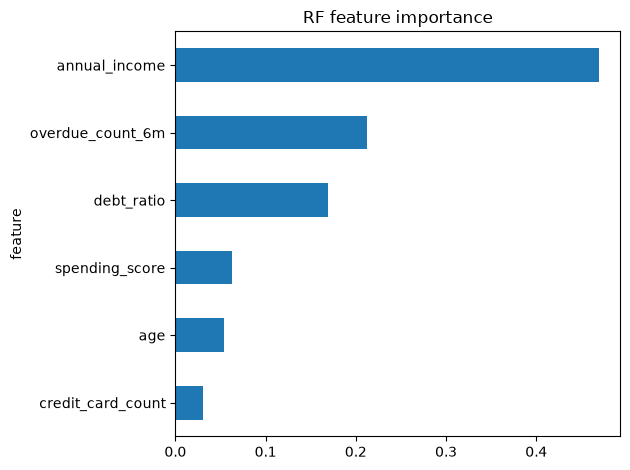

In [54]:
importance_table.plot.barh(x="feature", y="importance", legend=False, title="RF feature importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**출력 읽기:** 상위 세 변수가 정답 생성에 쓰인 세 변수와 같다. 쓰이지 않은 세 변수도 0은 아니다. 이 방식은 값의 종류가 많은 변수를 부풀리는 경향이 있기 때문이다. 중요도는 "모델이 많이 쓴 정도"이지 "그 변수가 연체의 원인"이라는 뜻이 아니다.

## D. Learning Curve — 데이터가 많아지면 나아질까

Train의 20%, 50%, 100%만 써서 학습하고, 각 크기에서 학습한 데이터의 점수(Train)와 교차검증 점수(Validation)를 비교한다.

- 두 선의 간격이 크면, 학습 데이터를 외워서 새 데이터에서는 덜 맞는다(**과대적합**).
- 두 선이 붙어 있는데 점수가 낮으면, 모델이나 데이터 자체의 한계다.

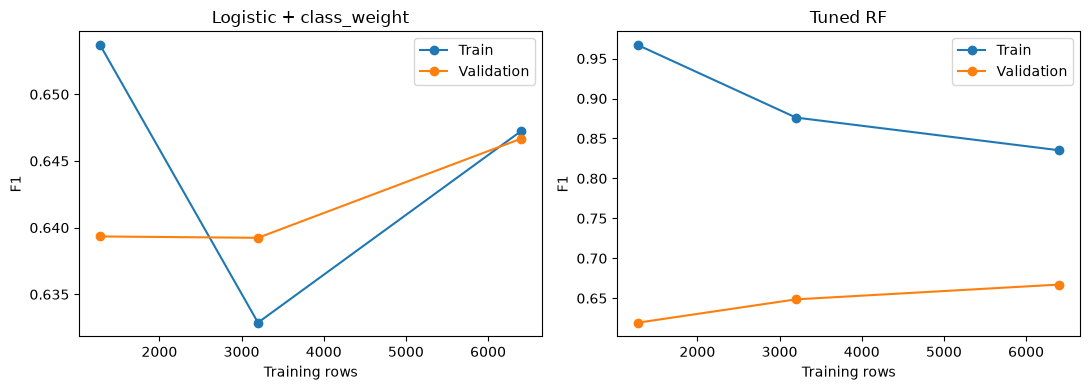

In [55]:
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
curve_models = [("Logistic + class_weight", balanced_logistic), ("Tuned RF", tuned_forest)]
for axis, (model_name, estimator) in zip(axes, curve_models):
    sizes, train_scores, validation_scores = learning_curve(
        clone(estimator), X_train, y_classification_train,
        train_sizes=[0.2, 0.5, 1.0], cv=classification_cv, scoring="f1",
    )
    axis.plot(sizes, train_scores.mean(axis=1), marker="o", label="Train")
    axis.plot(sizes, validation_scores.mean(axis=1), marker="o", label="Validation")
    axis.set_title(model_name)
    axis.set_xlabel("Training rows")
    axis.set_ylabel("F1")
    axis.legend()
plt.tight_layout()
plt.show()

**출력 읽기:** 로지스틱 회귀는 두 선이 붙어 있다. 데이터를 더 모아도 크게 나아지지 않는다. RF는 Train 점수가 훨씬 높아 간격이 크다. 깊은 나무가 학습 데이터의 잡음까지 외운 것이다.

## E. 범주형 변수와 나만의 변환기(Custom Transformer)

지금까지 입력은 모두 숫자였다. "20대·30대" 같은 **범주형** 변수는 모델에 넣기 전에 숫자로 바꿔야 한다. 연습을 위해 나이로 연령대 열을, 소득 × 부채 비율로 부채액 열을 만든다. CSV는 바꾸지 않고 계산만 한다. 입력이 달라졌으므로 본편 모델과 같은 점수가 나와야 하는 실험은 아니다.

먼저 보통 함수로 "표 → 새 열이 붙은 표"를 확인한다.

In [56]:
def add_derived_features(input_frame):
    result = input_frame.copy()
    age_bins = [20, 30, 40, 50, 60, 70]
    age_labels = ["20-29", "30-39", "40-49", "50-59", "60-69"]
    age_groups = pd.cut(result["age"], bins=age_bins, labels=age_labels, right=False)
    result["age_group"] = age_groups.astype(object).where(age_groups.notna(), np.nan)
    result["debt_amount"] = result["annual_income"] * result["debt_ratio"]
    return result

display(add_derived_features(X_train.head()))

,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m,age_group,debt_amount
1559,40,4613.0,16,0.98,7,0,40-49,4520.74
7318,40,5914.0,57,0.83,1,0,40-49,4908.62
4825,22,3466.0,11,0.90,2,0,20-29,3119.40
606,49,5333.0,17,0.48,9,0,40-49,2559.84
2383,38,1500.0,27,0.82,8,0,30-39,1230.00


이 함수를 Pipeline에 넣으려면 `fit`과 `transform`을 가진 클래스로 감싼다. 이것이 **Custom Transformer**다. 이 변환은 Train에서 배울 것이 없으므로 `fit`은 아무것도 하지 않고 자기 자신을 돌려준다.

범주형 열은 **원-핫 인코딩**으로 바꾼다. 연령대 하나를 "20-29인가? 30-39인가? …" 0/1 열 여러 개로 펼치는 방식이다. `ColumnTransformer`는 숫자 열과 범주 열에 서로 다른 전처리를 적용한다.

In [57]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

class LearningDerivedFeatures(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return add_derived_features(X)

numeric_columns = feature_columns + ["debt_amount"]
categorical_columns = ["age_group"]
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
column_preprocessor = ColumnTransformer([
    ("numeric", clone(numeric_preprocessor), numeric_columns),
    ("categorical", categorical_preprocessor, categorical_columns),
])
extended_logistic = Pipeline([
    ("derive", LearningDerivedFeatures()),
    ("columns", column_preprocessor),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000,
                                 random_state=RANDOM_STATE)),
])
extended_logistic.fit(X_train, y_classification_train)
display(extended_logistic.named_steps["columns"].get_feature_names_out())
display(pd.DataFrame([balanced_result,
                      evaluate_classifier("Logistic + class_weight + derived", extended_logistic,
                                          X_test, y_classification_test)]))

array(['numeric__age', 'numeric__annual_income',
       'numeric__spending_score', 'numeric__debt_ratio',
       'numeric__credit_card_count', 'numeric__overdue_count_6m',
       'numeric__debt_amount', 'categorical__age_group_20-29',
       'categorical__age_group_30-39', 'categorical__age_group_40-49',
       'categorical__age_group_50-59', 'categorical__age_group_60-69'],
      dtype=object)

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic + class_weight,0.8785,0.4965,0.875,0.6335,0.9505
1,Logistic + class_weight + derived,0.8770,0.4930,0.875,0.6306,0.9495


**출력 읽기:** 연령대 한 열이 `age_group_20-29` 같은 0/1 열 다섯 개로 펼쳐졌다. 점수는 새 열이 없을 때와 거의 같다. 연령대와 부채액은 정답을 만들 때 쓰이지 않은 정보이기 때문이다. 실제 대출 심사에서는 나이 같은 정보를 쓰는 것 자체가 공정성 검토 대상이 된다.